# Olist pipeline on Google Colab (Bronze -> Silver -> Quality -> Gold -> Dashboard queries)

**Team 9 | Big Data Project Work | Checkpoint 4**

This is the Databricks pipeline (notebooks 01 to 05) converted to run on free Google Colab with open-source PySpark.

What changes compared with Databricks:
* Tables live in plain Spark databases `bronze`, `silver`, `gold` (no Unity Catalog), stored as Parquet instead of Delta.
* Raw CSVs are read from `/content/raw_files/`.
* `display()` is replaced by a small helper that shows a pandas table.
* Unity Catalog governance steps (notebook 06: GRANTs, tags, lineage) cannot run here. Do those in Databricks.

Use this for testing and for the Colab run. For the submitted pipeline, lineage screenshot and Job, use Databricks.

**Run all cells top to bottom (Runtime -> Run all).** Tables vanish when the Colab session ends, so rerun from the top next time.

## 0. Setup: install PySpark, upload the Olist zip

In [106]:
!pip -q install pyspark==3.5.1

In [107]:
import os, zipfile, glob

os.makedirs("/content/raw_files", exist_ok=True)

# Option A: upload the Kaggle zip (archive.zip) from your laptop
from google.colab import files
uploaded = files.upload()          # pick archive.zip (or the 9 CSV files)

for name in uploaded:
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(name) as z:
            z.extractall("/content/raw_files")
    elif name.lower().endswith(".csv"):
        os.replace(name, f"/content/raw_files/{name}")

# Option B (instead of upload): copy from Google Drive
# from google.colab import drive; drive.mount('/content/drive')
# !unzip -oq "/content/drive/MyDrive/archive.zip" -d /content/raw_files

# Some zips put the CSVs in a sub-folder: flatten them
for f in glob.glob("/content/raw_files/**/*.csv", recursive=True):
    target = "/content/raw_files/" + os.path.basename(f)
    if f != target:
        os.replace(f, target)

print(sorted(os.listdir("/content/raw_files")))
assert len([f for f in os.listdir("/content/raw_files") if f.endswith(".csv")]) == 9, "Expected 9 CSV files"

Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv
Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [108]:
from pyspark.sql import SparkSession
from IPython.display import display as _ipy_display

spark = (SparkSession.builder
         .master("local[*]")
         .appName("olist")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())

for schema in ["bronze", "silver", "gold"]:
    spark.sql(f"CREATE DATABASE IF NOT EXISTS {schema}")

def display(obj):
    """Stand-in for Databricks display(): show up to 50 rows as a pandas table."""
    if hasattr(obj, "limit"):
        _ipy_display(obj.limit(50).toPandas())
    else:
        print(obj)

print("Spark", spark.version, "| databases:", [r[0] for r in spark.sql("SHOW DATABASES").collect()])

Spark 3.5.1 | databases: ['bronze', 'default', 'gold', 'silver']


## 1. Bronze ingestion (notebook 01)

In [109]:
import os

# Check uploaded CSV files

volume_path = "/content/raw_files/"

print(os.listdir(volume_path))

['olist_order_items_dataset.csv', 'product_category_name_translation.csv', 'olist_order_payments_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_customers_dataset.csv', 'olist_products_dataset.csv', 'olist_orders_dataset.csv', 'olist_sellers_dataset.csv']


In [110]:
from pyspark.sql import functions as F

In [111]:
orders_df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "false")
    .csv(
        "/content/raw_files/"
        "olist_orders_dataset.csv"
    )
)

display(orders_df.limit(10))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,None,None,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [112]:
orders_bronze = (
    orders_df
    .withColumn(
        "ingestion_timestamp",
        F.current_timestamp()
    )
    .withColumn(
        "source_file",
        F.lit("olist_orders_dataset.csv")
    )
)

(
    orders_bronze.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("bronze.orders")
)

print("Bronze orders table created successfully!")

print("Total records:", orders_bronze.count())

Bronze orders table created successfully!
Total records: 99441


In [113]:
display(
    spark.sql(
        "SELECT * FROM bronze.orders LIMIT 10"
    )
)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,ingestion_timestamp,source_file
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,None,None,2017-05-09 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv


In [114]:
files = {
    "customers": "olist_customers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

for table_name, filename in files.items():

    df = (
        spark.read
        .option("header", "true")
        .option("inferSchema", "false")
        .csv(volume_path + filename)
    )

    df = (
        df.withColumn(
            "ingestion_timestamp",
            F.current_timestamp()
        )
        .withColumn(
            "source_file",
            F.lit(filename)
        )
    )

    (
        df.write
        .format("parquet")
        .mode("overwrite")
        .saveAsTable(f"bronze.{table_name}")
    )

    print(
        f"{table_name}: {df.count()} records loaded"
    )

customers: 99441 records loaded
order_items: 112650 records loaded
order_payments: 103886 records loaded
order_reviews: 105189 records loaded
products: 32951 records loaded
sellers: 3095 records loaded
geolocation: 1000163 records loaded
category_translation: 71 records loaded


In [115]:
display(spark.sql("SHOW TABLES IN bronze"))

,namespace,tableName,isTemporary
0,bronze,category_translation,False
1,bronze,customers,False
2,bronze,geolocation,False
3,bronze,order_items,False
4,bronze,order_payments,False
5,bronze,order_reviews,False
6,bronze,orders,False
7,bronze,products,False
8,bronze,sellers,False


## 2. Silver transformation (notebook 02)

In [116]:
from pyspark.sql import functions as F

# Read data from Bronze layer
orders_df = spark.table("bronze.orders")

# Display first 10 records
display(orders_df.limit(10))

# Check total rows
print("Total orders:", orders_df.count())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,ingestion_timestamp,source_file
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,None,None,2017-05-09 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00,2026-11-18 11:11:49.415426,olist_orders_dataset.csv


Total orders: 99441


In [117]:
# Check missing values in each column

null_counts = orders_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in orders_df.columns
])

display(null_counts)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,ingestion_timestamp,source_file
0,0,0,0,0,160,1783,2965,0,0,0


In [118]:
# Step 4.4: Check and remove duplicate orders

print("Rows before cleaning:", orders_df.count())

duplicate_count = (
    orders_df.count()
    - orders_df.select("order_id").distinct().count()
)

print("Duplicate order IDs:", duplicate_count)

# Remove duplicate order records
orders_clean = orders_df.dropDuplicates(["order_id"])

print("Rows after cleaning:", orders_clean.count())

Rows before cleaning: 99441
Duplicate order IDs: 0
Rows after cleaning: 99441


In [119]:
# Step 4.5: Convert string dates to timestamps

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean = orders_clean.withColumn(
        column,
        F.to_timestamp(F.col(column))
    )

# Check converted data types
orders_clean.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [120]:
# Step 4.6: Calculate delivery delays

orders_clean = orders_clean.withColumn(
    "delivery_delay_days",
    F.when(
        F.col("order_delivered_customer_date").isNotNull(),
        F.datediff(
            F.col("order_delivered_customer_date"),
            F.col("order_estimated_delivery_date")
        )
    )
)

# Classify delivery status
orders_clean = orders_clean.withColumn(
    "delivery_status",
    F.when(
        F.col("order_delivered_customer_date").isNull(),
        "Not Delivered"
    )
    .when(
        F.col("delivery_delay_days") > 0,
        "Late"
    )
    .otherwise("On Time")
)

display(
    orders_clean.select(
        "order_id",
        "order_status",
        "delivery_delay_days",
        "delivery_status"
    ).limit(10)
)

,order_id,order_status,delivery_delay_days,delivery_status
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,-9,On Time
1,000229ec398224ef6ca0657da4fc703e,delivered,-14,On Time
2,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,-16,On Time
3,00048cc3ae777c65dbb7d2a0634bc1ea,delivered,-15,On Time
4,0005f50442cb953dcd1d21e1fb923495,delivered,-19,On Time
5,00061f2a7bc09da83e415a52dc8a4af1,delivered,-11,On Time
6,00063b381e2406b52ad429470734ebd5,delivered,0,On Time
7,0009792311464db532ff765bf7b182ae,delivered,-6,On Time
8,000c3e6612759851cc3cbb4b83257986,delivered,-13,On Time
9,000f25f4d72195062c040b12dce9a18a,delivered,-20,On Time


In [121]:
# Count orders by delivery status

display(
    orders_clean.groupBy("delivery_status")
    .count()
    .orderBy("delivery_status")
)

,delivery_status,count
0,Late,6535
1,Not Delivered,2965
2,On Time,89941


In [122]:
# Save transformed orders data

(
    orders_clean.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.orders")
)

print("Silver Orders table created successfully!")

Silver Orders table created successfully!


In [123]:
# Step 4.9: Load Bronze Order Items

from pyspark.sql import functions as F

items_df = spark.table("bronze.order_items")

print("Total order items:", items_df.count())

display(items_df.limit(10))

Total order items: 112650


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,ingestion_timestamp,source_file
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,2026-11-18 11:11:56.837205,olist_order_items_dataset.csv


In [124]:
# Check missing values in Order Items

null_counts = items_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in items_df.columns
])

display(null_counts)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,ingestion_timestamp,source_file
0,0,0,0,0,0,0,0,0,0


In [125]:
# Check duplicate order items

total_rows = items_df.count()

unique_items = items_df.select(
    "order_id",
    "order_item_id"
).distinct().count()

print("Total rows:", total_rows)
print("Unique order items:", unique_items)
print("Duplicate records:", total_rows - unique_items)

# Remove duplicate item keys
items_clean = items_df.dropDuplicates(
    ["order_id", "order_item_id"]
)

print("Rows after cleaning:", items_clean.count())

Total rows: 112650
Unique order items: 112650
Duplicate records: 0
Rows after cleaning: 112650


In [126]:
# Convert columns to appropriate data types

items_clean = (
    items_clean
    .withColumn(
        "order_item_id",
        F.col("order_item_id").cast("int")
    )
    .withColumn(
        "price",
        F.col("price").cast("double")
    )
    .withColumn(
        "freight_value",
        F.col("freight_value").cast("double")
    )
    .withColumn(
        "shipping_limit_date",
        F.to_timestamp("shipping_limit_date")
    )
)

items_clean.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- order_item_id: integer (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_value: double (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [127]:
# Calculate item total including freight

items_clean = items_clean.withColumn(
    "item_total_value",
    F.col("price") + F.col("freight_value")
)

display(
    items_clean.select(
        "order_id",
        "product_id",
        "price",
        "freight_value",
        "item_total_value"
    ).limit(10)
)

,order_id,product_id,price,freight_value,item_total_value
0,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,216.87
1,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,25.78
2,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,19.90,11.85,31.75
3,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,810.00,70.75,880.75
4,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,145.95,11.65,157.60
5,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,53.99,11.40,65.39
6,00061f2a7bc09da83e415a52dc8a4af1,d63c1011f49d98b976c352955b1c4bea,59.99,8.88,68.87
7,00063b381e2406b52ad429470734ebd5,f177554ea93259a5b282f24e33f65ab6,45.00,12.98,57.98
8,0009c9a17f916a706d71784483a5d643,3f27ac8e699df3d300ec4a5d8c5cf0b2,639.00,11.34,650.34
9,000aed2e25dbad2f9ddb70584c5a2ded,4fa33915031a8cde03dd0d3e8fb27f01,144.00,8.77,152.77


In [128]:
# Check invalid numeric values

invalid_items = items_clean.filter(
    F.col("price").isNull()
    | (F.col("price") < 0)
    | F.col("freight_value").isNull()
    | (F.col("freight_value") < 0)
)

print("Invalid price/freight records:",
      invalid_items.count())

display(invalid_items.limit(10))

Invalid price/freight records: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,ingestion_timestamp,source_file,item_total_value


In [129]:
# Save transformed data in Silver layer

(
    items_clean.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.order_items")
)

print("Silver Order Items table created successfully!")

print(
    "Total Silver records:",
    spark.table("silver.order_items").count()
)

Silver Order Items table created successfully!
Total Silver records: 112650


In [130]:
display(
    spark.sql("""
        SELECT
            order_id,
            order_item_id,
            product_id,
            seller_id,
            price,
            freight_value,
            item_total_value
        FROM silver.order_items
        LIMIT 10
    """)
)

,order_id,order_item_id,product_id,seller_id,price,freight_value,item_total_value
0,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.9,19.93,259.83
1,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.0,17.87,216.87
2,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.9,18.14,218.04
3,0006ec9db01a64e59a68b2c340bf65a7,1,99a4788cb24856965c36a24e339b6058,4a3ca9315b744ce9f8e9374361493884,74.0,23.32,97.32
4,0009792311464db532ff765bf7b182ae,1,8cab8abac59158715e0d70a36c807415,530ec6109d11eaaf87999465c6afee01,99.9,27.65,127.55
5,001021efaa8636c29475e7734483457d,1,5d7c23067ed3fc8c6e699b9373d5890b,6560211a19b47992c3666cc44a7e94c0,49.0,15.10,64.10
6,00119ff934e539cf26f92b9ef0cdfed8,1,21b1c2f67a9aafb5af0eb06c13b9dbda,c864036feaab8c1659f65ea4faebe1da,219.9,16.98,236.88
7,00125cb692d04887809806618a2a145f,1,1c0c0093a48f13ba70d0c6b0a9157cb7,41b39e28db005d9731d9d485a83b4c38,109.9,25.51,135.41
8,00130c0eee84a3d909e75bc08c5c3ca1,1,89321f94e35fc6d7903d36f74e351d40,16090f2ca825584b5a147ab24aa30c86,27.9,7.94,35.84
9,00137e170939bba5a3134e2386413108,1,672e757f331900b9deea127a2a7b79fd,e59aa562b9f8076dd550fcddf0e73491,397.0,24.65,421.65


In [131]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Load Bronze Order Reviews table
reviews_df = spark.table("bronze.order_reviews")

print("Total review records:", reviews_df.count())

display(reviews_df.limit(10))

Total review records: 105189


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,ingestion_timestamp,source_file
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,None,None,2018-01-18 00:00:00,2018-01-18 21:46:59,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,None,None,2018-03-10 00:00:00,2018-03-11 03:05:13,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,None,None,2018-02-17 00:00:00,2018-02-18 14:36:24,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,None,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,None,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,None,None,2018-04-13 00:00:00,2018-04-16 00:39:37,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,None,None,2017-07-16 00:00:00,2017-07-18 19:30:34,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,None,None,2018-08-14 00:00:00,2018-08-14 21:36:06,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,None,None,2017-05-17 00:00:00,2017-05-18 12:05:37,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22 00:00:00,2018-05-23 16:45:47,2026-11-18 11:12:04.763106,olist_order_reviews_dataset.csv


In [132]:
# Check missing values in reviews dataset

null_counts = reviews_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in reviews_df.columns
])

display(null_counts)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,ingestion_timestamp,source_file
0,1,2330,2497,93013,63321,9164,9187,0,0


In [133]:
# Check duplicate review IDs and multiple reviews per order

print("Total rows:", reviews_df.count())

print(
    "Duplicate review IDs:",
    reviews_df.count()
    - reviews_df.select("review_id").distinct().count()
)

print(
    "Additional reviews for repeated order IDs:",
    reviews_df.count()
    - reviews_df.select("order_id").distinct().count()
)

display(
    reviews_df.groupBy("order_id")
    .count()
    .filter(F.col("count") > 1)
    .orderBy(F.desc("count"))
    .limit(10)
)

Total rows: 105189
Duplicate review IDs: 1232
Additional reviews for repeated order IDs: 4626


,order_id,count
0,None,2330
1,2017-12-19 00:00:00,16
2,2017-12-16 00:00:00,16
3,2018-05-15 00:00:00,16
4,2018-04-11 00:00:00,15
5,2018-08-18 00:00:00,15
6,2018-02-24 00:00:00,15
7,2018-03-21 00:00:00,15
8,2017-12-06 00:00:00,14
9,2018-08-28 00:00:00,13


In [134]:
# Convert review score and timestamps

reviews_clean = (
    reviews_df
    .withColumn(
        "review_score",
        F.col("review_score").cast("int")
    )
    .withColumn(
        "review_creation_date",
        F.to_timestamp("review_creation_date")
    )
    .withColumn(
        "review_answer_timestamp",
        F.to_timestamp("review_answer_timestamp")
    )
)

reviews_clean.printSchema()

root
 |-- review_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- review_score: integer (nullable = true)
 |-- review_comment_title: string (nullable = true)
 |-- review_comment_message: string (nullable = true)
 |-- review_creation_date: timestamp (nullable = true)
 |-- review_answer_timestamp: timestamp (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [135]:
# Inspect the original Bronze review data

reviews_df = spark.table("bronze.order_reviews")

display(
    reviews_df.select(
        "review_id",
        "order_id",
        "review_score",
        "review_creation_date",
        "review_answer_timestamp"
    ).limit(10)
)

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01 00:00:00,2018-03-02 10:26:53
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,2018-04-13 00:00:00,2018-04-16 00:39:37
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,2017-07-16 00:00:00,2017-07-18 19:30:34
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,2018-08-14 00:00:00,2018-08-14 21:36:06
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,2017-05-17 00:00:00,2017-05-18 12:05:37
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,2018-05-22 00:00:00,2018-05-23 16:45:47


In [136]:
reviews_df.printSchema()

root
 |-- review_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- review_score: string (nullable = true)
 |-- review_comment_title: string (nullable = true)
 |-- review_comment_message: string (nullable = true)
 |-- review_creation_date: string (nullable = true)
 |-- review_answer_timestamp: string (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [137]:
# Identify non-numeric review scores

display(
    reviews_df.filter(
        F.expr("try_cast(review_score AS INT)").isNull()
    ).select(
        "review_id",
        "order_id",
        "review_score",
        "review_creation_date"
    ).limit(20)
)

,review_id,order_id,review_score,review_creation_date
0,",2018-02-16 00:00:00,2018-02-20 10:52:22",None,None,None
1,A entrega foi efetuada muito antes do prazo dado.,None,None,None
2,O produto já começou a ser usado e até o presente,None,None,None
3,"sem problemas.""",2018-03-23 00:00:00,2018-04-01 00:27:51,None
4,Faltou Controle Remoto para Ar Condicionado Co...,2018-01-28 00:00:00,2018-02-04 11:06:15,None
5,Estou satisfeita,None,None,None
6,",2017-06-02 00:00:00,2017-06-03 13:12:07",None,None,None
7,",2017-08-09 00:00:00,2017-08-09 12:03:45",None,None,None
8,",2017-11-22 00:00:00,2017-11-22 14:45:40",None,None,None
9,"Muito obrigada.... """,2017-06-24 00:00:00,2017-06-29 13:48:21,None


In [138]:
reviews_fixed = (
    spark.read
    .option("header", "true")
    .option("multiLine", "true")
    .option("quote", '"')
    .option("escape", '"')
    .option("mode", "FAILFAST")
    .csv(
        "/content/raw_files/"
        "olist_order_reviews_dataset.csv"
    )
)

display(
    reviews_fixed.select(
        "review_id",
        "order_id",
        "review_score",
        "review_creation_date"
    ).limit(10)
)

,review_id,order_id,review_score,review_creation_date
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18 00:00:00
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10 00:00:00
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17 00:00:00
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21 00:00:00
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01 00:00:00
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,2018-04-13 00:00:00
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,2017-07-16 00:00:00
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,2018-08-14 00:00:00
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,2017-05-17 00:00:00
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,2018-05-22 00:00:00


In [139]:
from pyspark.sql import functions as F

# Check invalid review scores in the repaired dataset
invalid_count = reviews_fixed.filter(
    F.expr("try_cast(review_score AS INT)").isNull()
    | ~F.expr("try_cast(review_score AS INT)").between(1, 5)
).count()

print("Total review records:", reviews_fixed.count())
print("Invalid review scores:", invalid_count)

Total review records: 100000
Invalid review scores: 0


In [140]:
# Add Bronze ingestion metadata
reviews_bronze_fixed = (
    reviews_fixed
    .withColumn(
        "ingestion_timestamp",
        F.current_timestamp()
    )
    .withColumn(
        "source_file",
        F.lit("olist_order_reviews_dataset.csv")
    )
)

# Replace incorrectly parsed Bronze table
(
    reviews_bronze_fixed.write
    .format("parquet")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("bronze.order_reviews")
)

print("Bronze Reviews table repaired successfully!")

Bronze Reviews table repaired successfully!


In [141]:
reviews_df = spark.table("bronze.order_reviews")

reviews_clean = (
    reviews_df
    .withColumn(
        "review_score",
        F.col("review_score").cast("int")
    )
    .withColumn(
        "review_creation_date",
        F.to_timestamp("review_creation_date")
    )
    .withColumn(
        "review_answer_timestamp",
        F.to_timestamp("review_answer_timestamp")
    )
)

display(
    reviews_clean.select(
        "review_id",
        "order_id",
        "review_score",
        "review_creation_date"
    ).limit(10)
)

,review_id,order_id,review_score,review_creation_date
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,2018-04-13
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,2017-07-16
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,2018-08-14
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,2017-05-17
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,2018-05-22


In [142]:
invalid_reviews = reviews_clean.filter(
    F.col("review_score").isNull()
    | ~F.col("review_score").between(1, 5)
)

print("Invalid review scores:", invalid_reviews.count())

display(invalid_reviews.limit(10))

Invalid review scores: 0


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,ingestion_timestamp,source_file


In [143]:
from pyspark.sql import functions as F

# Load Products dataset
products_df = spark.table("bronze.products")

print("Total Products:", products_df.count())

display(products_df.limit(10))

Total Products: 32951


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,ingestion_timestamp,source_file
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14,2026-11-18 11:12:07.464340,olist_products_dataset.csv
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20,2026-11-18 11:12:07.464340,olist_products_dataset.csv
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15,2026-11-18 11:12:07.464340,olist_products_dataset.csv
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26,2026-11-18 11:12:07.464340,olist_products_dataset.csv
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13,2026-11-18 11:12:07.464340,olist_products_dataset.csv
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,60,745,1,200,38,5,11,2026-11-18 11:12:07.464340,olist_products_dataset.csv
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,56,1272,4,18350,70,24,44,2026-11-18 11:12:07.464340,olist_products_dataset.csv
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56,184,2,900,40,8,40,2026-11-18 11:12:07.464340,olist_products_dataset.csv
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,57,163,1,400,27,13,17,2026-11-18 11:12:07.464340,olist_products_dataset.csv
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,36,1156,1,600,17,10,12,2026-11-18 11:12:07.464340,olist_products_dataset.csv


In [144]:
# Check missing values in products dataset

null_counts = products_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in products_df.columns
])

display(null_counts)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,ingestion_timestamp,source_file
0,0,610,610,610,610,2,2,2,2,0,0


In [145]:
# Check duplicate product IDs

total_products = products_df.count()

unique_products = products_df.select(
    "product_id"
).distinct().count()

print("Total products:", total_products)
print("Unique product IDs:", unique_products)
print("Duplicate product IDs:",
      total_products - unique_products)

# View duplicated product IDs
display(
    products_df.groupBy("product_id")
    .count()
    .filter(F.col("count") > 1)
    .limit(10)
)

Total products: 32951
Unique product IDs: 32951
Duplicate product IDs: 0


,product_id,count


In [146]:
# Convert product measurements to numeric types

numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products_clean = products_df

for column in numeric_columns:
    products_clean = products_clean.withColumn(
        column,
        F.expr(f"try_cast({column} AS DOUBLE)")
    )

products_clean.printSchema()

root
 |-- product_id: string (nullable = true)
 |-- product_category_name: string (nullable = true)
 |-- product_name_lenght: double (nullable = true)
 |-- product_description_lenght: double (nullable = true)
 |-- product_photos_qty: double (nullable = true)
 |-- product_weight_g: double (nullable = true)
 |-- product_length_cm: double (nullable = true)
 |-- product_height_cm: double (nullable = true)
 |-- product_width_cm: double (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [147]:
# Calculate product volume in cubic centimeters

products_clean = products_clean.withColumn(
    "product_volume_cm3",
    F.col("product_length_cm")
    * F.col("product_height_cm")
    * F.col("product_width_cm")
)

display(
    products_clean.select(
        "product_id",
        "product_weight_g",
        "product_volume_cm3"
    ).limit(10)
)

,product_id,product_weight_g,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,225.0,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,1000.0,10800.0
2,96bd76ec8810374ed1b65e291975717f,154.0,2430.0
3,cef67bcfe19066a932b7673e239eb23d,371.0,2704.0
4,9dc1a7de274444849c219cff195d0b71,625.0,4420.0
5,41d3672d4792049fa1779bb35283ed13,200.0,2090.0
6,732bd381ad09e530fe0a5f457d81becb,18350.0,73920.0
7,2548af3e6e77a690cf3eb6368e9ab61e,900.0,12800.0
8,37cc742be07708b53a98702e77a21a02,400.0,5967.0
9,8c92109888e8cdf9d66dc7e463025574,600.0,2040.0


In [148]:
# Load category translation table

translations_df = spark.table(
    "bronze.category_translation"
)

display(translations_df.limit(10))

,product_category_name,product_category_name_english,ingestion_timestamp,source_file
0,beleza_saude,health_beauty,2026-11-18 11:12:16.312663,product_category_name_translation.csv
1,informatica_acessorios,computers_accessories,2026-11-18 11:12:16.312663,product_category_name_translation.csv
2,automotivo,auto,2026-11-18 11:12:16.312663,product_category_name_translation.csv
3,cama_mesa_banho,bed_bath_table,2026-11-18 11:12:16.312663,product_category_name_translation.csv
4,moveis_decoracao,furniture_decor,2026-11-18 11:12:16.312663,product_category_name_translation.csv
5,esporte_lazer,sports_leisure,2026-11-18 11:12:16.312663,product_category_name_translation.csv
6,perfumaria,perfumery,2026-11-18 11:12:16.312663,product_category_name_translation.csv
7,utilidades_domesticas,housewares,2026-11-18 11:12:16.312663,product_category_name_translation.csv
8,telefonia,telephony,2026-11-18 11:12:16.312663,product_category_name_translation.csv
9,relogios_presentes,watches_gifts,2026-11-18 11:12:16.312663,product_category_name_translation.csv


In [149]:
display(
    translations_df.groupBy("product_category_name")
    .count()
    .filter(F.col("count") > 1)
)

,product_category_name,count


In [150]:
# Clean translation table

translations_clean = (
    translations_df
    .select(
        "product_category_name",
        "product_category_name_english"
    )
    .dropDuplicates(["product_category_name"])
)

# Join products with English categories
products_enriched = products_clean.join(
    translations_clean,
    on="product_category_name",
    how="left"
)

# Use Portuguese category if translation is unavailable
products_enriched = products_enriched.withColumn(
    "category_english",
    F.coalesce(
        F.col("product_category_name_english"),
        F.col("product_category_name"),
        F.lit("Unknown")
    )
)

display(
    products_enriched.select(
        "product_id",
        "product_category_name",
        "category_english"
    ).limit(10)
)

,product_id,product_category_name,category_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,musical_instruments
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,cool_stuff
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,furniture_decor
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,home_appliances
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,toys


In [151]:
# Identify negative or zero measurements

invalid_products = products_enriched.filter(
    (F.col("product_weight_g") <= 0)
    | (F.col("product_length_cm") <= 0)
    | (F.col("product_height_cm") <= 0)
    | (F.col("product_width_cm") <= 0)
)

print(
    "Products with invalid measurements:",
    invalid_products.count()
)

display(invalid_products.limit(10))

Products with invalid measurements: 4


,product_category_name,product_id,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,ingestion_timestamp,source_file,product_volume_cm3,product_category_name_english,category_english
0,cama_mesa_banho,81781c0fed9fe1ad6e8c81fca1e1cb08,51.0,529.0,1.0,0.0,30.0,25.0,30.0,2026-11-18 11:12:07.464340,olist_products_dataset.csv,22500.0,bed_bath_table,bed_bath_table
1,cama_mesa_banho,8038040ee2a71048d4bdbbdc985b69ab,48.0,528.0,1.0,0.0,30.0,25.0,30.0,2026-11-18 11:12:07.464340,olist_products_dataset.csv,22500.0,bed_bath_table,bed_bath_table
2,cama_mesa_banho,36ba42dd187055e1fbe943b2d11430ca,53.0,528.0,1.0,0.0,30.0,25.0,30.0,2026-11-18 11:12:07.464340,olist_products_dataset.csv,22500.0,bed_bath_table,bed_bath_table
3,cama_mesa_banho,e673e90efa65a5409ff4196c038bb5af,53.0,528.0,1.0,0.0,30.0,25.0,30.0,2026-11-18 11:12:07.464340,olist_products_dataset.csv,22500.0,bed_bath_table,bed_bath_table


In [152]:
(
    translations_clean.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.category_translation")
)

In [153]:
(
    products_enriched.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.products")
)

print("Silver Products table created successfully!")

print(
    "Total Silver products:",
    spark.table("silver.products").count()
)

Silver Products table created successfully!
Total Silver products: 32951


In [154]:
# Check product counts by English category

display(
    spark.table("silver.products")
    .groupBy("category_english")
    .count()
    .orderBy(F.desc("count"))
    .limit(15)
)

,category_english,count
0,bed_bath_table,3029
1,sports_leisure,2867
2,furniture_decor,2657
3,health_beauty,2444
4,housewares,2335
5,auto,1900
6,computers_accessories,1639
7,toys,1411
8,watches_gifts,1329
9,telephony,1134


In [155]:
from pyspark.sql import functions as F

# Load Bronze Customers table
customers_df = spark.table("bronze.customers")

print("Total customer records:", customers_df.count())

display(customers_df.limit(10))

Total customer records: 99441


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,ingestion_timestamp,source_file
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,04534,sao paulo,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG,2026-11-18 11:11:54.036862,olist_customers_dataset.csv


In [156]:
# Check missing values in customer records

customer_nulls = customers_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in customers_df.columns
])

display(customer_nulls)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,ingestion_timestamp,source_file
0,0,0,0,0,0,0,0


In [157]:
# Check duplicate customer IDs

customer_duplicates = (
    customers_df.groupBy("customer_id")
    .count()
    .filter(F.col("count") > 1)
)

print("Duplicate customer IDs:", customer_duplicates.count())

display(customer_duplicates.limit(10))

Duplicate customer IDs: 0


,customer_id,count


In [158]:
# Standardize customer location fields

customers_clean = (
    customers_df
    .withColumn(
        "customer_city",
        F.lower(F.trim(F.col("customer_city")))
    )
    .withColumn(
        "customer_state",
        F.upper(F.trim(F.col("customer_state")))
    )
    .withColumn(
        "customer_zip_code_prefix",
        F.lpad(
            F.trim(F.col("customer_zip_code_prefix")),
            5,
            "0"
        )
    )
)

display(customers_clean.limit(10))

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,ingestion_timestamp,source_file
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,04534,sao paulo,SP,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR,2026-11-18 11:11:54.036862,olist_customers_dataset.csv
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG,2026-11-18 11:11:54.036862,olist_customers_dataset.csv


In [159]:
# Customers by state

display(
    customers_clean.groupBy("customer_state")
    .count()
    .orderBy(F.desc("count"))
)

,customer_state,count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


In [160]:
# Save cleaned Customers table

(
    customers_clean.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.customers")
)

print("Silver Customers table created successfully!")

Silver Customers table created successfully!


In [161]:
# Load Bronze Sellers table

sellers_df = spark.table("bronze.sellers")

print("Total seller records:", sellers_df.count())

display(sellers_df.limit(10))

Total seller records: 3095


,seller_id,seller_zip_code_prefix,seller_city,seller_state,ingestion_timestamp,source_file
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
5,c240c4061717ac1806ae6ee72be3533b,20920,rio de janeiro,RJ,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
6,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,PE,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
7,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
8,768a86e36ad6aae3d03ee3c6433d61df,01529,sao paulo,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
9,ccc4bbb5f32a6ab2b7066a4130f114e3,80310,curitiba,PR,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv


In [162]:
# Check missing values in seller records

seller_nulls = sellers_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in sellers_df.columns
])

display(seller_nulls)

,seller_id,seller_zip_code_prefix,seller_city,seller_state,ingestion_timestamp,source_file
0,0,0,0,0,0,0


In [163]:
# Check duplicate seller IDs

seller_duplicates = (
    sellers_df.groupBy("seller_id")
    .count()
    .filter(F.col("count") > 1)
)

print("Duplicate seller IDs:", seller_duplicates.count())

display(seller_duplicates.limit(10))

Duplicate seller IDs: 0


,seller_id,count


In [164]:
# Standardize seller location data

sellers_clean = (
    sellers_df
    .withColumn(
        "seller_city",
        F.lower(F.trim(F.col("seller_city")))
    )
    .withColumn(
        "seller_state",
        F.upper(F.trim(F.col("seller_state")))
    )
    .withColumn(
        "seller_zip_code_prefix",
        F.lpad(
            F.trim(F.col("seller_zip_code_prefix")),
            5,
            "0"
        )
    )
)

display(sellers_clean.limit(10))

,seller_id,seller_zip_code_prefix,seller_city,seller_state,ingestion_timestamp,source_file
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
5,c240c4061717ac1806ae6ee72be3533b,20920,rio de janeiro,RJ,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
6,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,PE,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
7,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
8,768a86e36ad6aae3d03ee3c6433d61df,01529,sao paulo,SP,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv
9,ccc4bbb5f32a6ab2b7066a4130f114e3,80310,curitiba,PR,2026-11-18 11:12:08.366344,olist_sellers_dataset.csv


In [165]:
# Distribution of sellers by state

display(
    sellers_clean.groupBy("seller_state")
    .count()
    .orderBy(F.desc("count"))
)

,seller_state,count
0,SP,1849
1,PR,349
2,MG,244
3,SC,190
4,RJ,171
5,RS,129
6,GO,40
7,DF,30
8,ES,23
9,BA,19


In [166]:
# Save cleaned Sellers table

(
    sellers_clean.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.sellers")
)

print("Silver Sellers table created successfully!")

Silver Sellers table created successfully!


In [167]:
# Verify Customers and Sellers Silver tables

display(
    spark.sql("""
        SELECT 'customers' AS table_name,
               COUNT(*) AS total_records
        FROM silver.customers

        UNION ALL

        SELECT 'sellers' AS table_name,
               COUNT(*) AS total_records
        FROM silver.sellers
    """)
)

,table_name,total_records
0,customers,99441
1,sellers,3095


In [168]:
from pyspark.sql import functions as F

# Load Bronze Order Payments
payments_df = spark.table("bronze.order_payments")

print("Total payment records:", payments_df.count())

display(payments_df.limit(10))

Total payment records: 103886


,order_id,payment_sequential,payment_type,payment_installments,payment_value,ingestion_timestamp,source_file
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95,2026-11-18 11:12:02.609808,olist_order_payments_dataset.csv


In [169]:
# Check missing values in payments

payment_nulls = payments_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in payments_df.columns
])

display(payment_nulls)

,order_id,payment_sequential,payment_type,payment_installments,payment_value,ingestion_timestamp,source_file
0,0,0,0,0,0,0,0


In [170]:
# Check duplicate payment keys

payment_duplicates = (
    payments_df
    .groupBy("order_id", "payment_sequential")
    .count()
    .filter(F.col("count") > 1)
)

print(
    "Duplicate payment keys:",
    payment_duplicates.count()
)

display(payment_duplicates.limit(10))

Duplicate payment keys: 0


,order_id,payment_sequential,count


In [171]:
# Convert payment columns to correct types

payments_clean = (
    payments_df
    .withColumn(
        "payment_sequential",
        F.expr("try_cast(payment_sequential AS INT)")
    )
    .withColumn(
        "payment_installments",
        F.expr("try_cast(payment_installments AS INT)")
    )
    .withColumn(
        "payment_value",
        F.expr("try_cast(payment_value AS DOUBLE)")
    )
)

payments_clean.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- payment_sequential: integer (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- payment_installments: integer (nullable = true)
 |-- payment_value: double (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [172]:
# Standardize payment methods

payments_clean = payments_clean.withColumn(
    "payment_type",
    F.lower(F.trim(F.col("payment_type")))
)

display(
    payments_clean.groupBy("payment_type")
    .count()
    .orderBy(F.desc("count"))
)

,payment_type,count
0,credit_card,76795
1,boleto,19784
2,voucher,5775
3,debit_card,1529
4,not_defined,3


In [173]:
# Identify invalid payment records

invalid_payments = payments_clean.filter(
    F.col("payment_value").isNull()
    | (F.col("payment_value") < 0)
    | F.col("payment_sequential").isNull()
    | (F.col("payment_sequential") <= 0)
    | F.col("payment_installments").isNull()
    | (F.col("payment_installments") < 0)
)

print(
    "Invalid payment records:",
    invalid_payments.count()
)

display(invalid_payments.limit(10))

Invalid payment records: 0


,order_id,payment_sequential,payment_type,payment_installments,payment_value,ingestion_timestamp,source_file


In [174]:
# Aggregate payments at order level

payments_summary = payments_clean.groupBy(
    "order_id"
).agg(
    F.round(
        F.sum("payment_value"), 2
    ).alias("total_payment_value"),

    F.count("*").alias("payment_count"),

    F.countDistinct(
        "payment_type"
    ).alias("payment_method_count")
)

display(payments_summary.limit(10))

,order_id,total_payment_value,payment_count,payment_method_count
0,298fcdf1f73eb413e4d26d01b25bc1cd,96.12,1,1
1,adfbf6c2a620196f9a3ec747491c72b7,67.50,1,1
2,96de2b7f7f3c401fbee3eef068376da6,32.15,1,1
3,9acd1ccfbc6445c0cad9ee9ddb48054c,81.78,1,1
4,6cdb86865449a92089579ea715e1c1d1,52.57,1,1
5,7cb79316d2abe37e16ec83a07afb2895,52.53,2,2
6,621b8e90f6fd06a792af8bdbbaf64a92,85.14,2,1
7,e74c5411558a7a26de918d23a07e1cef,42.86,1,1
8,940d83f3286808e4f8b1a7ac975b2aa9,76.02,1,1
9,85be7c94bcd3f908fc877157ee21f755,72.75,1,1


In [175]:
# Save cleaned payment records

(
    payments_clean.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.order_payments")
)

print("Silver Order Payments table created!")

Silver Order Payments table created!


In [176]:
# Save order-level payment summary

(
    payments_summary.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.payment_summary")
)

print("Payment Summary table created!")

Payment Summary table created!


In [177]:
# Verify Silver Payment tables

display(
    spark.sql("""
        SELECT
            'order_payments' AS table_name,
            COUNT(*) AS total_records
        FROM silver.order_payments

        UNION ALL

        SELECT
            'payment_summary' AS table_name,
            COUNT(*) AS total_records
        FROM silver.payment_summary
    """)
)

,table_name,total_records
0,order_payments,103886
1,payment_summary,99440


In [178]:
# Payment method analysis

display(
    payments_clean.groupBy("payment_type")
    .agg(
        F.count("*").alias("transactions"),
        F.round(
            F.sum("payment_value"), 2
        ).alias("total_payment_value")
    )
    .orderBy(F.desc("total_payment_value"))
)

,payment_type,transactions,total_payment_value
0,credit_card,76795,12542084.19
1,boleto,19784,2869361.27
2,voucher,5775,379436.87
3,debit_card,1529,217989.79
4,not_defined,3,0.00


In [179]:
from pyspark.sql import functions as F

# Load Bronze Geolocation dataset
geo_df = spark.table("bronze.geolocation")

print("Total geolocation records:", geo_df.count())

display(geo_df.limit(10))

Total geolocation records: 1000163


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,ingestion_timestamp,source_file
0,01037,-23.54562128115268,-46.63929204800168,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
1,01046,-23.546081127035535,-46.64482029837157,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
2,01046,-23.54612896641469,-46.64295148361138,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
3,01041,-23.5443921648681,-46.63949930627844,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
4,01035,-23.541577961711493,-46.64160722329613,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
5,01012,-23.547762303364266,-46.63536053788448,são paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
6,01047,-23.546273112412678,-46.64122516971552,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
7,01013,-23.546923208436723,-46.6342636964915,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
8,01029,-23.543769055769133,-46.63427784085132,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv
9,01011,-23.547639550320632,-46.63603162315495,sao paulo,SP,2026-11-18 11:12:08.798611,olist_geolocation_dataset.csv


In [180]:
# Check missing values

geo_nulls = geo_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in geo_df.columns
])

display(geo_nulls)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,ingestion_timestamp,source_file
0,0,0,0,0,0,0,0


In [181]:
# Standardize geographical data

geo_clean = (
    geo_df
    .withColumn(
        "geolocation_zip_code_prefix",
        F.lpad(
            F.trim(F.col("geolocation_zip_code_prefix")),
            5,
            "0"
        )
    )
    .withColumn(
        "geolocation_lat",
        F.expr("try_cast(geolocation_lat AS DOUBLE)")
    )
    .withColumn(
        "geolocation_lng",
        F.expr("try_cast(geolocation_lng AS DOUBLE)")
    )
    .withColumn(
        "geolocation_city",
        F.lower(F.trim(F.col("geolocation_city")))
    )
    .withColumn(
        "geolocation_state",
        F.upper(F.trim(F.col("geolocation_state")))
    )
)

geo_clean.printSchema()

root
 |-- geolocation_zip_code_prefix: string (nullable = true)
 |-- geolocation_lat: double (nullable = true)
 |-- geolocation_lng: double (nullable = true)
 |-- geolocation_city: string (nullable = true)
 |-- geolocation_state: string (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = true)
 |-- source_file: string (nullable = true)



In [182]:
# Validate geographical coordinates

invalid_geo = geo_clean.filter(
    F.col("geolocation_lat").isNull()
    | F.col("geolocation_lng").isNull()
    | ~F.col("geolocation_lat").between(-90, 90)
    | ~F.col("geolocation_lng").between(-180, 180)
)

print(
    "Invalid coordinate records:",
    invalid_geo.count()
)

display(invalid_geo.limit(10))

Invalid coordinate records: 0


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,ingestion_timestamp,source_file


In [183]:
# Count exact duplicate geographic records

geo_columns = [
    "geolocation_zip_code_prefix",
    "geolocation_lat",
    "geolocation_lng",
    "geolocation_city",
    "geolocation_state"
]

total_rows = geo_clean.count()

unique_rows = geo_clean.select(
    *geo_columns
).distinct().count()

print("Total records:", total_rows)
print("Unique geographical records:", unique_rows)
print("Exact duplicates:", total_rows - unique_rows)

Total records: 1000163
Unique geographical records: 738332
Exact duplicates: 261831


In [184]:
# Remove exact geographic duplicates

geo_deduplicated = geo_clean.dropDuplicates(
    [
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng",
        "geolocation_city",
        "geolocation_state"
    ]
)

print(
    "Records after deduplication:",
    geo_deduplicated.count()
)

Records after deduplication: 738332


In [185]:
# Retain valid coordinates for geographic aggregation

geo_valid = geo_deduplicated.filter(
    F.col("geolocation_zip_code_prefix").isNotNull()
    & F.col("geolocation_lat").between(-90, 90)
    & F.col("geolocation_lng").between(-180, 180)
)

# One representative coordinate per ZIP prefix
geo_summary = (
    geo_valid
    .groupBy("geolocation_zip_code_prefix")
    .agg(
        F.avg("geolocation_lat").alias("avg_latitude"),
        F.avg("geolocation_lng").alias("avg_longitude"),
        F.count("*").alias("location_count")
    )
)

display(geo_summary.limit(10))

,geolocation_zip_code_prefix,avg_latitude,avg_longitude,location_count
0,01036,-23.541976,-46.640842,13
1,01022,-23.544781,-46.632063,12
2,01004,-23.549829,-46.634792,14
3,01015,-23.547756,-46.631738,7
4,01138,-23.522198,-46.654774,14
5,01103,-23.535596,-46.629045,16
6,01121,-23.527701,-46.635016,32
7,01106,-23.530213,-46.628173,19
8,01129,-23.523812,-46.643878,20
9,01134,-23.519484,-46.651667,8


In [186]:
# Save cleaned geolocation data

(
    geo_deduplicated.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.geolocation")
)

print("Silver Geolocation table created!")

Silver Geolocation table created!


In [187]:
# Save ZIP-code summary

(
    geo_summary.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.geolocation_summary")
)

print("Geolocation Summary table created!")

Geolocation Summary table created!


In [188]:
# Verify saved geolocation tables

display(
    spark.sql("""
        SELECT
            'geolocation' AS table_name,
            COUNT(*) AS total_records
        FROM silver.geolocation

        UNION ALL

        SELECT
            'geolocation_summary' AS table_name,
            COUNT(*) AS total_records
        FROM silver.geolocation_summary
    """)
)

,table_name,total_records
0,geolocation,738332
1,geolocation_summary,19015


In [189]:
# Geolocation records by state

display(
    spark.table("silver.geolocation")
    .groupBy("geolocation_state")
    .count()
    .orderBy(F.desc("count"))
)

,geolocation_state,count
0,SP,285976
1,MG,101353
2,RJ,78836
3,RS,48093
4,PR,45059
5,SC,30191
6,BA,27720
7,GO,15601
8,PE,13162
9,ES,12632


In [190]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Read corrected Bronze reviews
reviews_df = spark.table("bronze.order_reviews")

print("Total Bronze reviews:", reviews_df.count())

display(
    reviews_df.select(
        "review_id",
        "order_id",
        "review_score",
        "review_creation_date",
        "review_answer_timestamp"
    ).limit(10)
)

Total Bronze reviews: 100000


,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01 00:00:00,2018-03-02 10:26:53
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,2018-04-13 00:00:00,2018-04-16 00:39:37
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,2017-07-16 00:00:00,2017-07-18 19:30:34
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,2018-08-14 00:00:00,2018-08-14 21:36:06
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,2017-05-17 00:00:00,2017-05-18 12:05:37
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,2018-05-22 00:00:00,2018-05-23 16:45:47


In [191]:
# Convert data types safely

reviews_clean = (
    reviews_df
    .withColumn(
        "review_score",
        F.expr("try_cast(review_score AS INT)")
    )
    .withColumn(
        "review_creation_date",
        F.to_timestamp("review_creation_date")
    )
    .withColumn(
        "review_answer_timestamp",
        F.to_timestamp("review_answer_timestamp")
    )
)

# Select latest review for each order
review_window = (
    Window.partitionBy("order_id")
    .orderBy(
        F.col("review_answer_timestamp").desc_nulls_last(),
        F.col("review_creation_date").desc_nulls_last(),
        F.col("review_id").desc()
    )
)

reviews_final = (
    reviews_clean
    .withColumn(
        "row_num",
        F.row_number().over(review_window)
    )
    .filter(F.col("row_num") == 1)
    .drop("row_num")
    .select(
        "review_id",
        "order_id",
        "review_score",
        "review_creation_date",
        "review_answer_timestamp"
    )
)

print("Cleaned review records:", reviews_final.count())

display(reviews_final.limit(10))

Cleaned review records: 99441


,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,97ca439bc427b48bc1cd7177abe71365,00010242fe8c5a6d1ba2dd792cb16214,5,2017-09-21,2017-09-22 10:57:03
1,0c5b33dea94867d1ac402749e5438e8b,000229ec398224ef6ca0657da4fc703e,5,2018-01-23,2018-01-23 16:06:31
2,940144190dcba6351888cafa43f3a3a5,00042b26cf59d7ce69dfabb4e55b4fd9,5,2017-03-02,2017-03-03 10:54:59
3,5e4e50af3b7960b7a10d86ec869509e8,00048cc3ae777c65dbb7d2a0634bc1ea,4,2017-05-23,2017-05-24 19:00:09
4,5c0b7e34ed85ec659bb064902d878e7a,0005f50442cb953dcd1d21e1fb923495,4,2018-07-05,2018-07-05 23:17:04
5,7e92c32ae297ef950ee69781d9f1760c,00061f2a7bc09da83e415a52dc8a4af1,5,2018-03-30,2018-03-30 04:04:56
6,5595c192e3c1566ab4e7a2748b8ed297,00063b381e2406b52ad429470734ebd5,5,2018-08-08,2018-08-09 00:12:30
7,236ccf78a5c4c350c18fdc1ae12b0187,0009792311464db532ff765bf7b182ae,5,2018-08-23,2018-08-23 16:11:56
8,51b9186876d4708a91786f8517fe7106,000c3e6612759851cc3cbb4b83257986,5,2017-08-20,2017-08-20 19:56:31
9,775038877f3c507777081ff685e14a60,000f25f4d72195062c040b12dce9a18a,4,2018-03-23,2018-03-24 04:17:06


In [192]:
# Create the missing Silver Reviews table

(
    reviews_final.write
    .format("parquet")
    .mode("overwrite")
    .saveAsTable("silver.order_reviews")
)

print("SUCCESS: Silver Order Reviews table created!")

SUCCESS: Silver Order Reviews table created!


In [193]:
# Verify the table exists

print(
    "Table exists:",
    spark.catalog.tableExists(
        "silver.order_reviews"
    )
)

print(
    "Total records:",
    spark.table(
        "silver.order_reviews"
    ).count()
)

Table exists: True
Total records: 99441


## 3. Quality checks (notebook 03)

In [194]:
from datetime import datetime
import uuid
from pyspark.sql import functions as F

LAYER = "silver"
LOG_TABLE = "silver.dq_log"
RUN_ID = uuid.uuid4().hex[:8]
RUN_TS = datetime.now()
results = []

def tbl(layer, name):
    return spark.table(f"{layer}.{name}")

def log_check(check, table, metric, threshold, ok, severity, note=""):
    """Store one check result in memory and print it."""
    status = "PASS" if ok else ("FAIL" if severity == "critical" else "WARN")
    results.append((RUN_ID, RUN_TS, LAYER, check, table,
                    float(metric), float(threshold), severity, status, note))
    print(f"[{status}] {table:<18} {check:<42} value={metric}  limit={threshold}")

print("Run id:", RUN_ID)

Run id: 9d20ced3


In [195]:
# (bronze table, silver table, max share of rows allowed to drop, why rows may drop)
ROW_RULES = [
    ("orders",               "orders",               0.00, "Only duplicate order_id removed"),
    ("order_items",          "order_items",          0.00, "Only duplicate (order_id, order_item_id) removed"),
    ("order_payments",       "order_payments",       0.00, "No rows removed"),
    ("order_reviews",        "order_reviews",        0.05, "Keeps the latest review per order"),
    ("customers",            "customers",            0.00, "No rows removed"),
    ("sellers",              "sellers",              0.00, "No rows removed"),
    ("products",             "products",             0.00, "Left join to translation must not add or drop rows"),
    ("category_translation", "category_translation", 0.00, "No rows removed"),
    ("geolocation",          "geolocation",          0.40, "Exact duplicate coordinates removed (about a quarter of the file)"),
]

for b, s, max_drop, why in ROW_RULES:
    rows_in = tbl("bronze", b).count()
    rows_out = tbl("silver", s).count()
    drop = (rows_in - rows_out) / rows_in
    ok = -1e-9 <= drop <= max_drop + 1e-9
    log_check("rows_drop_share", s, round(drop, 4), max_drop, ok, "critical",
              f"{rows_in} in, {rows_out} out. {why}")

[PASS] orders             rows_drop_share                            value=0.0  limit=0.0
[PASS] order_items        rows_drop_share                            value=0.0  limit=0.0
[PASS] order_payments     rows_drop_share                            value=0.0  limit=0.0
[PASS] order_reviews      rows_drop_share                            value=0.0056  limit=0.05
[PASS] customers          rows_drop_share                            value=0.0  limit=0.0
[PASS] sellers            rows_drop_share                            value=0.0  limit=0.0
[PASS] products           rows_drop_share                            value=0.0  limit=0.0
[PASS] category_translation rows_drop_share                            value=0.0  limit=0.0
[PASS] geolocation        rows_drop_share                            value=0.2618  limit=0.4


In [196]:
# (table, column, max null share, severity, note)
NULL_RULES = [
    ("orders",      "order_id",                      0.00, "critical", ""),
    ("orders",      "customer_id",                   0.00, "critical", ""),
    ("orders",      "order_purchase_timestamp",      0.00, "critical", ""),
    ("orders",      "order_estimated_delivery_date", 0.00, "critical", ""),
    ("orders",      "order_delivered_customer_date", 0.05, "warn",
     "Empty for canceled, unavailable and in-transit orders - expected"),
    ("order_items", "order_id",                      0.00, "critical", ""),
    ("order_items", "product_id",                    0.00, "critical", ""),
    ("order_items", "seller_id",                     0.00, "critical", ""),
    ("order_items", "price",                         0.00, "critical", ""),
    ("order_reviews", "review_score",                0.00, "critical", ""),
    ("customers",   "customer_unique_id",            0.00, "critical", ""),
    ("sellers",     "seller_id",                     0.00, "critical", ""),
    ("products",    "product_category_name",         0.03, "warn",
     "Products without a category are mapped to 'Unknown' in silver"),
]

for t, c, limit, sev, note in NULL_RULES:
    df = tbl("silver", t)
    total = df.count()
    nulls = df.filter(F.col(c).isNull()).count()
    rate = nulls / total
    log_check(f"null_rate:{c}", t, round(rate, 4), limit, rate <= limit, sev,
              f"{nulls} of {total} null. {note}".strip())

[PASS] orders             null_rate:order_id                         value=0.0  limit=0.0
[PASS] orders             null_rate:customer_id                      value=0.0  limit=0.0
[PASS] orders             null_rate:order_purchase_timestamp         value=0.0  limit=0.0
[PASS] orders             null_rate:order_estimated_delivery_date    value=0.0  limit=0.0
[PASS] orders             null_rate:order_delivered_customer_date    value=0.0298  limit=0.05
[PASS] order_items        null_rate:order_id                         value=0.0  limit=0.0
[PASS] order_items        null_rate:product_id                       value=0.0  limit=0.0
[PASS] order_items        null_rate:seller_id                        value=0.0  limit=0.0
[PASS] order_items        null_rate:price                            value=0.0  limit=0.0
[PASS] order_reviews      null_rate:review_score                     value=0.0  limit=0.0
[PASS] customers          null_rate:customer_unique_id               value=0.0  limit=0.0
[PASS]

In [197]:
KEY_RULES = [
    ("orders",         ["order_id"]),
    ("order_items",    ["order_id", "order_item_id"]),
    ("order_reviews",  ["order_id"]),
    ("order_payments", ["order_id", "payment_sequential"]),
    ("customers",      ["customer_id"]),
    ("sellers",        ["seller_id"]),
    ("products",       ["product_id"]),
]

for t, keys in KEY_RULES:
    df = tbl("silver", t)
    dup = df.count() - df.select(*keys).distinct().count()
    log_check("duplicate_keys:" + "+".join(keys), t, dup, 0, dup == 0, "critical")

[PASS] orders             duplicate_keys:order_id                    value=0  limit=0
[PASS] order_items        duplicate_keys:order_id+order_item_id      value=0  limit=0
[PASS] order_reviews      duplicate_keys:order_id                    value=0  limit=0
[PASS] order_payments     duplicate_keys:order_id+payment_sequential value=0  limit=0
[PASS] customers          duplicate_keys:customer_id                 value=0  limit=0
[PASS] sellers            duplicate_keys:seller_id                   value=0  limit=0
[PASS] products           duplicate_keys:product_id                  value=0  limit=0


In [198]:
# (child table, child key, parent table, parent key, severity)
FK_RULES = [
    ("order_items",    "order_id",    "orders",    "order_id",    "critical"),
    ("order_items",    "product_id",  "products",  "product_id",  "critical"),
    ("order_items",    "seller_id",   "sellers",   "seller_id",   "critical"),
    ("orders",         "customer_id", "customers", "customer_id", "critical"),
    ("order_reviews",  "order_id",    "orders",    "order_id",    "warn"),
    ("order_payments", "order_id",    "orders",    "order_id",    "warn"),
]

for child, ck, parent, pk, sev in FK_RULES:
    c = tbl("silver", child)
    p = tbl("silver", parent).select(F.col(pk).alias("_pk")).distinct()
    orphans = c.join(p, c[ck] == p["_pk"], "left_anti").count()
    log_check(f"orphan_keys:{ck}->{parent}", child, orphans, 0, orphans == 0, sev)

# Orders that have no item rows (not an error, but they cannot appear in the item-level fact)
orders = tbl("silver", "orders")
no_items = orders.join(tbl("silver", "order_items").select("order_id").distinct(), "order_id", "left_anti")
share = no_items.count() / orders.count()
log_check("orders_without_items_share", "orders", round(share, 4), 0.01, share <= 0.01, "warn",
          "Mostly canceled/unavailable orders that never reached the item stage")
display(no_items.groupBy("order_status").count().orderBy(F.desc("count")))

[PASS] order_items        orphan_keys:order_id->orders               value=0  limit=0
[PASS] order_items        orphan_keys:product_id->products           value=0  limit=0
[PASS] order_items        orphan_keys:seller_id->sellers             value=0  limit=0
[PASS] orders             orphan_keys:customer_id->customers         value=0  limit=0
[PASS] order_reviews      orphan_keys:order_id->orders               value=0  limit=0
[PASS] order_payments     orphan_keys:order_id->orders               value=0  limit=0
[PASS] orders             orders_without_items_share                 value=0.0078  limit=0.01


,order_status,count
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


In [199]:
o = tbl("silver", "orders")
n_orders = o.count()

def share_check(name, table, bad_count, total, limit, sev, note=""):
    share = bad_count / total
    log_check(name, table, round(share, 5), limit, share <= limit, sev, f"{bad_count} of {total} rows. {note}".strip())

# Delivery date logic
share_check("delivered_before_purchase", "orders",
            o.filter(F.col("order_delivered_customer_date") < F.col("order_purchase_timestamp")).count(),
            n_orders, 0.0, "warn", "Customer delivery date earlier than purchase date")
share_check("carrier_pickup_before_purchase", "orders",
            o.filter(F.col("order_delivered_carrier_date") < F.col("order_purchase_timestamp")).count(),
            n_orders, 0.005, "warn", "Carrier date earlier than purchase date: source timestamp errors, not used in gold KPIs")
share_check("delivered_before_carrier_pickup", "orders",
            o.filter(F.col("order_delivered_customer_date") < F.col("order_delivered_carrier_date")).count(),
            n_orders, 0.001, "warn", "Source timestamp errors, we only use purchase, delivered and estimated dates")
share_check("status_delivered_without_date", "orders",
            o.filter((F.col("order_status") == "delivered") & F.col("order_delivered_customer_date").isNull()).count(),
            n_orders, 0.001, "warn", "Left out of delivery KPIs in gold (no delivery date to compare)")
share_check("delivery_date_without_status_delivered", "orders",
            o.filter((F.col("order_status") != "delivered") & F.col("order_delivered_customer_date").isNotNull()).count(),
            n_orders, 0.001, "warn", "Left out of delivery KPIs in gold (status is not delivered)")
share_check("late_flag_inconsistent", "orders",
            o.filter(((F.col("delivery_status") == "Late") & (F.col("delivery_delay_days") <= 0))
                     | ((F.col("delivery_status") == "On Time") & (F.col("delivery_delay_days") > 0))).count(),
            n_orders, 0.0, "critical", "delivery_status must agree with delivery_delay_days")

# Prices and payments
items = tbl("silver", "order_items")
share_check("bad_price_or_freight", "order_items",
            items.filter(F.col("price").isNull() | (F.col("price") <= 0)
                         | F.col("freight_value").isNull() | (F.col("freight_value") < 0)).count(),
            items.count(), 0.0, "warn", "Price must be above 0 and freight not negative")

pay = tbl("silver", "order_payments")
share_check("negative_payment_value", "order_payments",
            pay.filter(F.col("payment_value") < 0).count(), pay.count(), 0.0, "warn")
share_check("zero_payment_value", "order_payments",
            pay.filter(F.col("payment_value") == 0).count(), pay.count(), 0.001, "warn",
            "Zero-value rows are mostly the not_defined payment type, payments are not used in Q1 to Q3 revenue")

# Reviews and products
rev = tbl("silver", "order_reviews")
share_check("review_score_out_of_range", "order_reviews",
            rev.filter(F.col("review_score").isNull() | ~F.col("review_score").between(1, 5)).count(),
            rev.count(), 0.0, "critical", "Scores must be whole numbers 1 to 5")
prod = tbl("silver", "products")
share_check("product_weight_not_positive", "products",
            prod.filter(F.col("product_weight_g") <= 0).count(), prod.count(), 0.001, "warn",
            "Weight is not used in Q1 to Q3")

# Revenue reconciliation: sum of price in bronze (as text) must equal sum in silver
bronze_price = tbl("bronze", "order_items").agg(F.sum(F.expr("try_cast(price AS DOUBLE)"))).first()[0]
silver_price = items.agg(F.sum("price")).first()[0]
diff = abs(bronze_price - silver_price)
log_check("revenue_reconciliation_abs_diff", "order_items", round(diff, 4), 0.01, diff <= 0.01, "critical",
          f"bronze sum {bronze_price:,.2f} vs silver sum {silver_price:,.2f}")

[PASS] orders             delivered_before_purchase                  value=0.0  limit=0.0
[PASS] orders             carrier_pickup_before_purchase             value=0.00167  limit=0.005
[PASS] orders             delivered_before_carrier_pickup            value=0.00023  limit=0.001
[PASS] orders             status_delivered_without_date              value=8e-05  limit=0.001
[PASS] orders             delivery_date_without_status_delivered     value=6e-05  limit=0.001
[PASS] orders             late_flag_inconsistent                     value=0.0  limit=0.0
[PASS] order_items        bad_price_or_freight                       value=0.0  limit=0.0
[PASS] order_payments     negative_payment_value                     value=0.0  limit=0.0
[PASS] order_payments     zero_payment_value                         value=9e-05  limit=0.001
[PASS] order_reviews      review_score_out_of_range                  value=0.0  limit=0.0
[PASS] products           product_weight_not_positive                value=0

In [200]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, TimestampType

LOG_SCHEMA = StructType([
    StructField("run_id",     StringType()),
    StructField("run_ts",     TimestampType()),
    StructField("layer",      StringType()),
    StructField("check_name", StringType()),
    StructField("table_name", StringType()),
    StructField("metric",     DoubleType()),
    StructField("threshold",  DoubleType()),
    StructField("severity",   StringType()),
    StructField("status",     StringType()),
    StructField("note",       StringType()),
])

(spark.createDataFrame(results, LOG_SCHEMA)
      .write.format("parquet").mode("append").saveAsTable(LOG_TABLE))

summary = (spark.table(LOG_TABLE).filter(F.col("run_id") == RUN_ID)
           .groupBy("status").count().orderBy("status"))
display(summary)

failed = [r for r in results if r[8] == "FAIL"]
if failed:
    raise Exception(f"{len(failed)} critical quality check(s) failed. See {LOG_TABLE}, run_id={RUN_ID}")
print("No critical failures. Safe to build gold.")

,status,count
0,PASS,48


No critical failures. Safe to build gold.


In [201]:
display(
    spark.table(LOG_TABLE)
    .filter((F.col("run_id") == RUN_ID) & (F.col("status") == "WARN"))
    .select("table_name", "check_name", "metric", "threshold", "note")
)

,table_name,check_name,metric,threshold,note


## 4. Gold star schema (notebook 04)

In [202]:
from datetime import datetime
import uuid
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, TimestampType

CATALOG = "olist"
SILVER = "silver"
GOLD = "gold"
LOG_TABLE = f"{SILVER}.dq_log"

EXCLUDED_STATUSES = ["canceled", "unavailable"]
PARTIAL_BEFORE = "2017-01"   # months strictly before this are incomplete
PARTIAL_AFTER = "2018-08"    # months strictly after this are incomplete
MIN_ORDERS = 30              # minimum delivered orders for a fair late-rate ranking

REGIONS = {
    "North":      ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Northeast":  ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Central-West": ["DF", "GO", "MT", "MS"],
    "Southeast":  ["ES", "MG", "RJ", "SP"],
    "South":      ["PR", "RS", "SC"],
}

def sk(col):
    """Deterministic surrogate key from a source id."""
    return F.xxhash64(F.col(col))

def date_key(col):
    return F.date_format(F.col(col), "yyyyMMdd").cast("int")

def region_of(col):
    expr = F.lit("Unknown")
    for region, states in REGIONS.items():
        expr = F.when(F.col(col).isin(states), region).otherwise(expr)
    return expr

def save_gold(df, name, comment):
    (df.write.format("parquet").mode("overwrite")
       .option("overwriteSchema", "true").saveAsTable(f"{GOLD}.{name}"))
    safe = comment.replace("'", "''")
    try:
        spark.sql(f"COMMENT ON TABLE {GOLD}.{name} IS '{safe}'")
    except Exception:
        pass   # table comments need Unity Catalog; skipped on Colab
    print(f"{name:<34}{spark.table(f'{GOLD}.{name}').count():>10,} rows")

In [203]:
orders    = spark.table(f"{SILVER}.orders")
items     = spark.table(f"{SILVER}.order_items")
reviews   = spark.table(f"{SILVER}.order_reviews").select("order_id", "review_score")
customers = spark.table(f"{SILVER}.customers")
sellers   = spark.table(f"{SILVER}.sellers")
products  = spark.table(f"{SILVER}.products")
payments  = spark.table(f"{SILVER}.payment_summary")
geo       = spark.table(f"{SILVER}.geolocation_summary")

print("orders:", orders.count(), "| items:", items.count(), "| reviews:", reviews.count())

orders: 99441 | items: 112650 | reviews: 99441


In [204]:
# ---- dim_date: one row per calendar day from first purchase to last estimated/delivered date
bounds = orders.agg(
    F.min(F.to_date("order_purchase_timestamp")).alias("first_day"),
    F.greatest(
        F.max(F.to_date("order_estimated_delivery_date")),
        F.max(F.to_date("order_delivered_customer_date")),
    ).alias("last_day"),
).first()

dim_date = (
    spark.range(1)
    .select(F.explode(F.sequence(F.lit(bounds["first_day"]), F.lit(bounds["last_day"]),
                                 F.expr("interval 1 day"))).alias("date"))
    .withColumn("date_key", F.date_format("date", "yyyyMMdd").cast("int"))
    .withColumn("year", F.year("date"))
    .withColumn("quarter", F.quarter("date"))
    .withColumn("month", F.month("date"))
    .withColumn("month_name", F.date_format("date", "MMMM"))
    .withColumn("year_month", F.date_format("date", "yyyy-MM"))
    .withColumn("day_of_week", F.date_format("date", "E"))
    .withColumn("is_weekend", F.dayofweek("date").isin(1, 7))
    .withColumn("is_partial_month",
                (F.col("year_month") < PARTIAL_BEFORE) | (F.col("year_month") > PARTIAL_AFTER))
    .select("date_key", "date", "year", "quarter", "month", "month_name",
            "year_month", "day_of_week", "is_weekend", "is_partial_month")
)

save_gold(dim_date, "dim_date", "Calendar dimension. is_partial_month marks 2016 and Sep-Oct 2018, which are incomplete in the source data.")

# ---- dim_customer (customer_id is one row per order in Olist; customer_unique_id identifies the repeat buyer)
geo_c = geo.select(F.col("geolocation_zip_code_prefix").alias("customer_zip_code_prefix"),
                   F.col("avg_latitude").alias("latitude"),
                   F.col("avg_longitude").alias("longitude"))

dim_customer = (
    customers.join(geo_c, "customer_zip_code_prefix", "left")
    .select(
        sk("customer_id").alias("customer_key"),
        "customer_id", "customer_unique_id",
        "customer_city", "customer_state",
        region_of("customer_state").alias("customer_region"),
        "customer_zip_code_prefix", "latitude", "longitude",
    )
)
save_gold(dim_customer, "dim_customer", "Customer dimension. Anonymised ids only, location at zip-prefix level. No names or contact data exist in the source.")

# ---- dim_seller
geo_s = geo.select(F.col("geolocation_zip_code_prefix").alias("seller_zip_code_prefix"),
                   F.col("avg_latitude").alias("latitude"),
                   F.col("avg_longitude").alias("longitude"))

dim_seller = (
    sellers.join(geo_s, "seller_zip_code_prefix", "left")
    .select(
        sk("seller_id").alias("seller_key"),
        "seller_id", "seller_city", "seller_state",
        region_of("seller_state").alias("seller_region"),
        "seller_zip_code_prefix", "latitude", "longitude",
    )
)
save_gold(dim_seller, "dim_seller", "Seller dimension. Anonymised seller ids, location at zip-prefix level.")

# ---- dim_product
dim_product = products.select(
    sk("product_id").alias("product_key"),
    "product_id",
    "category_english",
    F.col("product_category_name").alias("category_portuguese"),
    "product_photos_qty",
    "product_weight_g",
    "product_volume_cm3",
)
save_gold(dim_product, "dim_product", "Product dimension with English category (Unknown when the source has no category).")

dim_date                                 800 rows
dim_customer                          99,441 rows
dim_seller                             3,095 rows
dim_product                           32,951 rows


In [205]:
# An order is in "delivery scope" when it was really delivered and has a delivery date.
in_scope = (F.col("order_status") == "delivered") & F.col("order_delivered_customer_date").isNotNull()

order_cols = orders.select(
    "order_id", "customer_id", "order_status",
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
    "delivery_delay_days", "delivery_status",
)

# ---- fact_order_items: grain = one order item
fact_order_items = (
    items.join(order_cols, "order_id", "inner")          # no orphans: checked in notebook 03
         .join(reviews, "order_id", "left")
         .withColumn("is_delivered", in_scope)
         .select(
             "order_id", "order_item_id",
             sk("customer_id").alias("customer_key"),
             sk("seller_id").alias("seller_key"),
             sk("product_id").alias("product_key"),
             date_key("order_purchase_timestamp").alias("purchase_date_key"),
             date_key("order_delivered_customer_date").alias("delivered_date_key"),
             date_key("order_estimated_delivery_date").alias("estimated_date_key"),
             "order_status",
             "delivery_status",
             "is_delivered",
             F.when(F.col("is_delivered"), F.col("delivery_delay_days")).alias("delivery_delay_days"),
             F.when(F.col("is_delivered"),
                    F.datediff("order_delivered_customer_date", "order_purchase_timestamp")).alias("actual_delivery_days"),
             F.when(F.col("is_delivered"), (F.col("delivery_delay_days") > 0).cast("int")).alias("is_late"),
             (~F.col("order_status").isin(EXCLUDED_STATUSES)).alias("is_valid_sale"),
             "price", "freight_value", "item_total_value",
             "review_score",
         )
)
save_gold(fact_order_items, "fact_order_items",
          "Fact table, one row per order item. Revenue = price. is_late is only set for delivered orders. review_score repeats on every item of an order, so count reviews on fact_orders.")

# ---- fact_orders: grain = one order (safe for review and late-rate counting)
order_totals = items.groupBy("order_id").agg(
    F.count("*").alias("item_count"),
    F.countDistinct("seller_id").alias("seller_count"),
    F.round(F.sum("price"), 2).alias("order_revenue"),
    F.round(F.sum("freight_value"), 2).alias("order_freight"),
)

d = F.col("delivery_delay_days")
delay_bucket = (F.when(~F.col("is_delivered"), "Not delivered")
                 .when(d <= 0, "On time")
                 .when(d <= 3, "1-3 days late")
                 .when(d <= 7, "4-7 days late")
                 .when(d <= 14, "8-14 days late")
                 .otherwise("15+ days late"))
bucket_sort = (F.when(~F.col("is_delivered"), 9)
                .when(d <= 0, 0).when(d <= 3, 1).when(d <= 7, 2).when(d <= 14, 3).otherwise(4))

fact_orders = (
    orders.join(order_totals, "order_id", "left")
          .join(reviews, "order_id", "left")
          .join(payments.select("order_id", "total_payment_value"), "order_id", "left")
          .withColumn("is_delivered", in_scope)
          .fillna(0, subset=["item_count", "seller_count", "order_revenue", "order_freight"])
          .select(
              "order_id",
              sk("customer_id").alias("customer_key"),
              date_key("order_purchase_timestamp").alias("purchase_date_key"),
              "order_status",
              "is_delivered",
              F.when(F.col("is_delivered"), F.col("delivery_delay_days")).alias("delivery_delay_days"),
              F.when(F.col("is_delivered"),
                     F.datediff("order_delivered_customer_date", "order_purchase_timestamp")).alias("actual_delivery_days"),
              F.when(F.col("is_delivered"), (F.col("delivery_delay_days") > 0).cast("int")).alias("is_late"),
              delay_bucket.alias("delay_bucket"),
              bucket_sort.alias("delay_bucket_sort"),
              "review_score",
              F.when(F.col("review_score").isNotNull(), (F.col("review_score") <= 2).cast("int")).alias("is_low_review"),
              "item_count", "seller_count", "order_revenue", "order_freight",
              "total_payment_value",
          )
)
save_gold(fact_orders, "fact_orders",
          "Fact table, one row per order. Use this table for late rate and review score so multi-item orders are not counted twice.")

fact_order_items                     112,650 rows
fact_orders                           99,441 rows


In [206]:
g_items = spark.table(f"{GOLD}.fact_order_items")
g_orders = spark.table(f"{GOLD}.fact_orders")
g_date = spark.table(f"{GOLD}.dim_date")
g_cust = spark.table(f"{GOLD}.dim_customer")
g_sell = spark.table(f"{GOLD}.dim_seller")
g_prod = spark.table(f"{GOLD}.dim_product")

item_view = (
    g_items
    .join(g_date.select(F.col("date_key").alias("purchase_date_key"), "year", "month", "year_month", "is_partial_month"),
          "purchase_date_key", "left")
    .join(g_prod.select("product_key", "category_english"), "product_key", "left")
    .join(g_cust.select("customer_key", "customer_state", "customer_region"), "customer_key", "left")
    .join(g_sell.select("seller_key", "seller_id", "seller_state", "seller_region"), "seller_key", "left")
)

# ---- Q1: monthly revenue and orders by category and customer state
agg_monthly_revenue = (
    item_view.filter(F.col("is_valid_sale"))
    .groupBy("year_month", "year", "month", "is_partial_month",
             "category_english", "customer_state", "customer_region")
    .agg(
        F.countDistinct("order_id").alias("orders"),
        F.count("*").alias("items"),
        F.round(F.sum("price"), 2).alias("revenue"),
        F.round(F.sum("freight_value"), 2).alias("freight"),
    )
)
save_gold(agg_monthly_revenue, "agg_monthly_revenue",
          "Q1. Monthly revenue, orders and items by product category and customer state (valid sales only). orders is not additive across categories.")

# ---- Q2 and Q3: late rate, review score and revenue for any grouping
def delivery_agg(group_cols):
    """Late rate by group. One row per (order, group) first, so an order is counted once per group."""
    pairs = (
        item_view.filter(F.col("is_delivered"))
        .groupBy("order_id", *group_cols)
        .agg(
            F.sum("price").alias("revenue"),
            F.max("is_late").alias("is_late"),
            F.max("review_score").alias("review_score"),     # same value on every item of an order
            F.max("delivery_delay_days").alias("delay_days"),
        )
    )
    late = F.col("is_late") == 1
    on_time = F.col("is_late") == 0
    return (
        pairs.groupBy(*group_cols)
        .agg(
            F.count("*").alias("delivered_orders"),
            F.sum("is_late").alias("late_orders"),
            F.round(F.avg("is_late") * 100, 2).alias("late_rate_pct"),
            F.round(F.avg(F.when(late, F.col("delay_days"))), 1).alias("avg_days_late"),
            F.count("review_score").alias("reviewed_orders"),
            F.round(F.avg("review_score"), 2).alias("avg_review_score"),
            F.round(F.avg(F.when(late, F.col("review_score"))), 2).alias("avg_review_late"),
            F.round(F.avg(F.when(on_time, F.col("review_score"))), 2).alias("avg_review_on_time"),
            F.round(F.sum("revenue"), 2).alias("revenue"),
            F.round(F.sum(F.when(late, F.col("revenue")).otherwise(0.0)), 2).alias("late_revenue"),
        )
        .withColumn("review_gap", F.round(F.col("avg_review_on_time") - F.col("avg_review_late"), 2))
        .withColumn("late_revenue_share_pct", F.round(F.col("late_revenue") / F.col("revenue") * 100, 2))
        .withColumn("meets_min_volume", F.col("delivered_orders") >= MIN_ORDERS)
    )

note = "Delivered orders only. An order with several sellers or categories counts once in each group. Groups under 30 delivered orders have meets_min_volume = false."
save_gold(delivery_agg(["seller_state", "seller_region"]),  "agg_delivery_by_seller_state",
          "Q2. Late rate, review score and revenue by seller state. " + note)
save_gold(delivery_agg(["seller_id", "seller_state"]),      "agg_delivery_by_seller",
          "Q2. Late rate, review score and revenue by seller. " + note)
save_gold(delivery_agg(["category_english"]),               "agg_delivery_by_category",
          "Q2. Late rate, review score and revenue by product category. " + note)
save_gold(delivery_agg(["customer_state", "customer_region"]), "agg_delivery_by_customer_state",
          "Q1/Q2. Late rate, review score and revenue by customer state. " + note)

# ---- Monthly late-rate trend (by purchase month)
agg_monthly_delivery = (
    g_orders.filter(F.col("is_delivered"))
    .join(g_date.select(F.col("date_key").alias("purchase_date_key"), "year_month", "is_partial_month"),
          "purchase_date_key", "left")
    .groupBy("year_month", "is_partial_month")
    .agg(
        F.count("*").alias("delivered_orders"),
        F.sum("is_late").alias("late_orders"),
        F.round(F.avg("is_late") * 100, 2).alias("late_rate_pct"),
        F.round(F.avg("review_score"), 2).alias("avg_review_score"),
    )
)
save_gold(agg_monthly_delivery, "agg_monthly_delivery",
          "Q2/Q3. Monthly late rate and average review score for delivered orders, by purchase month.")

# ---- Q3: review score by how late the order was (order level)
delivered_orders = g_orders.filter(F.col("is_delivered"))
total_revenue = delivered_orders.agg(F.sum("order_revenue")).first()[0]

agg_review_impact = (
    delivered_orders.groupBy("delay_bucket", "delay_bucket_sort")
    .agg(
        F.count("*").alias("orders"),
        F.count("review_score").alias("reviewed_orders"),
        F.round(F.avg("review_score"), 2).alias("avg_review_score"),
        F.round(F.avg("is_low_review") * 100, 1).alias("low_review_pct"),
        F.round(F.avg(F.when(F.col("review_score") == 5, 1.0).when(F.col("review_score").isNotNull(), 0.0)) * 100, 1).alias("five_star_pct"),
        F.round(F.sum("order_revenue"), 2).alias("revenue"),
    )
    .withColumn("revenue_share_pct", F.round(F.col("revenue") / F.lit(total_revenue) * 100, 2))
)
save_gold(agg_review_impact, "agg_review_impact",
          "Q3. Review score, low-review share (1 or 2 stars) and revenue by delivery delay bucket, delivered orders only.")

agg_monthly_revenue                   11,805 rows
agg_delivery_by_seller_state              22 rows
agg_delivery_by_seller                 2,970 rows
agg_delivery_by_category                  74 rows
agg_delivery_by_customer_state            27 rows
agg_monthly_delivery                      23 rows
agg_review_impact                          5 rows


In [207]:
RUN_ID = uuid.uuid4().hex[:8]
RUN_TS = datetime.now()
results = []

def log_check(check, table, metric, threshold, ok, severity, note=""):
    status = "PASS" if ok else ("FAIL" if severity == "critical" else "WARN")
    results.append((RUN_ID, RUN_TS, "gold", check, table, float(metric), float(threshold), severity, status, note))
    print(f"[{status}] {table:<30} {check:<36} value={metric}  limit={threshold}")

# Row counts must match silver
log_check("rowcount_diff_vs_silver", "fact_order_items",
          abs(spark.table(f"{GOLD}.fact_order_items").count() - items.count()), 0,
          spark.table(f"{GOLD}.fact_order_items").count() == items.count(), "critical",
          "Every silver order item must be in the fact")
log_check("rowcount_diff_vs_silver", "fact_orders",
          abs(spark.table(f"{GOLD}.fact_orders").count() - orders.count()), 0,
          spark.table(f"{GOLD}.fact_orders").count() == orders.count(), "critical",
          "Every silver order must be in the fact")

# Dimension keys must be unique
for dim, key in [("dim_date", "date_key"), ("dim_customer", "customer_key"),
                 ("dim_seller", "seller_key"), ("dim_product", "product_key")]:
    df = spark.table(f"{GOLD}.{dim}")
    dup = df.count() - df.select(key).distinct().count()
    log_check("duplicate_dimension_keys", dim, dup, 0, dup == 0, "critical")

# Every fact key must exist in its dimension
fi = spark.table(f"{GOLD}.fact_order_items")
for fk, dim, dk in [("customer_key", "dim_customer", "customer_key"),
                    ("seller_key", "dim_seller", "seller_key"),
                    ("product_key", "dim_product", "product_key"),
                    ("purchase_date_key", "dim_date", "date_key")]:
    dim_keys = spark.table(f"{GOLD}.{dim}").select(F.col(dk).alias("_k"))
    orphans = fi.join(dim_keys, fi[fk] == dim_keys["_k"], "left_anti").count()
    log_check(f"fact_key_orphans:{fk}", "fact_order_items", orphans, 0, orphans == 0, "critical")

# Revenue in the Q1 aggregate must equal revenue in the fact (valid sales)
fact_rev = fi.filter(F.col("is_valid_sale")).agg(F.sum("price")).first()[0]
agg_rev = spark.table(f"{GOLD}.agg_monthly_revenue").agg(F.sum("revenue")).first()[0]
rel = abs(fact_rev - agg_rev) / fact_rev
log_check("revenue_reconciliation_rel_diff", "agg_monthly_revenue", round(rel, 8), 0.0001, rel <= 0.0001, "critical",
          f"fact {fact_rev:,.2f} vs aggregate {agg_rev:,.2f}")

# Late orders in the aggregate must equal late orders in the order fact
fo = spark.table(f"{GOLD}.fact_orders")
fact_late = fo.filter(F.col("is_late") == 1).count()
agg_late = spark.table(f"{GOLD}.agg_delivery_by_customer_state").agg(F.sum("late_orders")).first()[0]
log_check("late_orders_reconciliation", "agg_delivery_by_customer_state", abs(fact_late - agg_late), 0,
          fact_late == agg_late, "critical", f"fact_orders {fact_late} vs aggregate {agg_late}")

# Delivered orders in the Q3 aggregate must equal delivered orders in the order fact
fact_deliv = fo.filter(F.col("is_delivered")).count()
agg_deliv = spark.table(f"{GOLD}.agg_review_impact").agg(F.sum("orders")).first()[0]
log_check("delivered_orders_reconciliation", "agg_review_impact", abs(fact_deliv - agg_deliv), 0,
          fact_deliv == agg_deliv, "critical", f"fact_orders {fact_deliv} vs aggregate {agg_deliv}")

# Save the log
LOG_SCHEMA = StructType([
    StructField("run_id", StringType()), StructField("run_ts", TimestampType()),
    StructField("layer", StringType()), StructField("check_name", StringType()),
    StructField("table_name", StringType()), StructField("metric", DoubleType()),
    StructField("threshold", DoubleType()), StructField("severity", StringType()),
    StructField("status", StringType()), StructField("note", StringType()),
])
(spark.createDataFrame(results, LOG_SCHEMA).write.format("parquet").mode("append").saveAsTable(LOG_TABLE))

failed = [r for r in results if r[8] == "FAIL"]
if failed:
    raise Exception(f"{len(failed)} gold validation check(s) failed. See {LOG_TABLE}, run_id={RUN_ID}")
print("Gold validation passed.")

[PASS] fact_order_items               rowcount_diff_vs_silver              value=0  limit=0
[PASS] fact_orders                    rowcount_diff_vs_silver              value=0  limit=0
[PASS] dim_date                       duplicate_dimension_keys             value=0  limit=0
[PASS] dim_customer                   duplicate_dimension_keys             value=0  limit=0
[PASS] dim_seller                     duplicate_dimension_keys             value=0  limit=0
[PASS] dim_product                    duplicate_dimension_keys             value=0  limit=0
[PASS] fact_order_items               fact_key_orphans:customer_key        value=0  limit=0
[PASS] fact_order_items               fact_key_orphans:seller_key          value=0  limit=0
[PASS] fact_order_items               fact_key_orphans:product_key         value=0  limit=0
[PASS] fact_order_items               fact_key_orphans:purchase_date_key   value=0  limit=0
[PASS] agg_monthly_revenue            revenue_reconciliation_rel_diff      value

In [208]:
display(spark.sql(f"SHOW TABLES IN {GOLD}"))

# Late vs on-time review score (the headline for Q3)
display(
    spark.table(f"{GOLD}.fact_orders").filter(F.col("is_delivered"))
    .groupBy(F.when(F.col("is_late") == 1, "Late").otherwise("On time").alias("delivery"))
    .agg(F.count("*").alias("orders"), F.round(F.avg("review_score"), 2).alias("avg_review_score"))
)

display(spark.table(f"{GOLD}.agg_review_impact").orderBy("delay_bucket_sort"))

,namespace,tableName,isTemporary
0,gold,agg_delivery_by_category,False
1,gold,agg_delivery_by_customer_state,False
2,gold,agg_delivery_by_seller,False
3,gold,agg_delivery_by_seller_state,False
4,gold,agg_monthly_delivery,False
5,gold,agg_monthly_revenue,False
6,gold,agg_review_impact,False
7,gold,dim_customer,False
8,gold,dim_date,False
9,gold,dim_product,False


,delivery,orders,avg_review_score
0,On time,89936,4.28
1,Late,6534,2.26


,delay_bucket,delay_bucket_sort,orders,reviewed_orders,avg_review_score,low_review_pct,five_star_pct,revenue,revenue_share_pct
0,On time,0,89936,89936,4.28,9.5,62.0,12234324.59,92.54
1,1-3 days late,1,1870,1870,3.28,32.4,33.0,250856.63,1.90
2,4-7 days late,2,1802,1802,2.09,68.1,13.7,287685.63,2.18
3,8-14 days late,3,1478,1478,1.67,80.4,6.8,229872.60,1.74
4,15+ days late,4,1384,1384,1.72,78.5,7.1,217509.48,1.65


05 Dashbaord


In [209]:
from IPython.display import display as _ipy_display

def display(obj):
    if hasattr(obj, "limit"):
        _ipy_display(obj.limit(50).toPandas())
    elif hasattr(obj, "head"):
        _ipy_display(obj)
    else:
        print(obj)

_needed = ["fact_orders", "dim_date", "dim_customer", "agg_monthly_revenue",
           "agg_delivery_by_seller_state", "agg_delivery_by_seller", "agg_delivery_by_category",
           "agg_delivery_by_customer_state", "agg_monthly_delivery", "agg_review_impact"]
_have = {r["tableName"] for r in spark.sql("SHOW TABLES IN gold").collect()}
_missing = [t for t in _needed if t not in _have]
assert not _missing, f"Gold tables missing {_missing}. Run the pipeline through the gold step in this session first."
print("Gold tables found. Building dashboard...")

Gold tables found. Building dashboard...


In [210]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("/content/dashboard", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def q(sql):
    return spark.sql(sql).toPandas()

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"/content/dashboard/{name}.png", dpi=150)
    plt.show()

Chart 1A: monthly revenue and orders (complete months only)

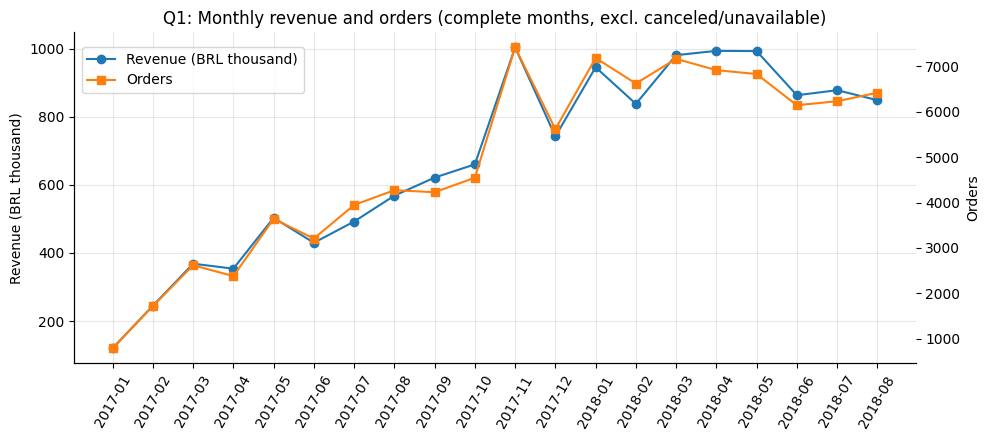

In [212]:
m = q('''
SELECT d.year_month, COUNT(*) AS orders, ROUND(SUM(f.order_revenue), 2) AS revenue
FROM gold.fact_orders f JOIN gold.dim_date d ON f.purchase_date_key = d.date_key
WHERE f.order_status NOT IN ('canceled', 'unavailable') AND f.item_count > 0 AND NOT d.is_partial_month
GROUP BY d.year_month ORDER BY d.year_month
''')
fig, ax1 = plt.subplots()
ax1.plot(m["year_month"], m["revenue"] / 1e3, color="tab:blue", marker="o", label="Revenue (BRL thousand)")
ax1.set_ylabel("Revenue (BRL thousand)")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(m["year_month"], m["orders"], color="tab:orange", marker="s", label="Orders")
ax2.set_ylabel("Orders")
ax1.set_title("Q1: Monthly revenue and orders (complete months, excl. canceled/unavailable)")
ax1.tick_params(axis="x", rotation=60)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.9))
save(fig, "q1a_monthly_revenue_orders")

Chart 1B: monthly revenue, top 10 categories (rest = Other)

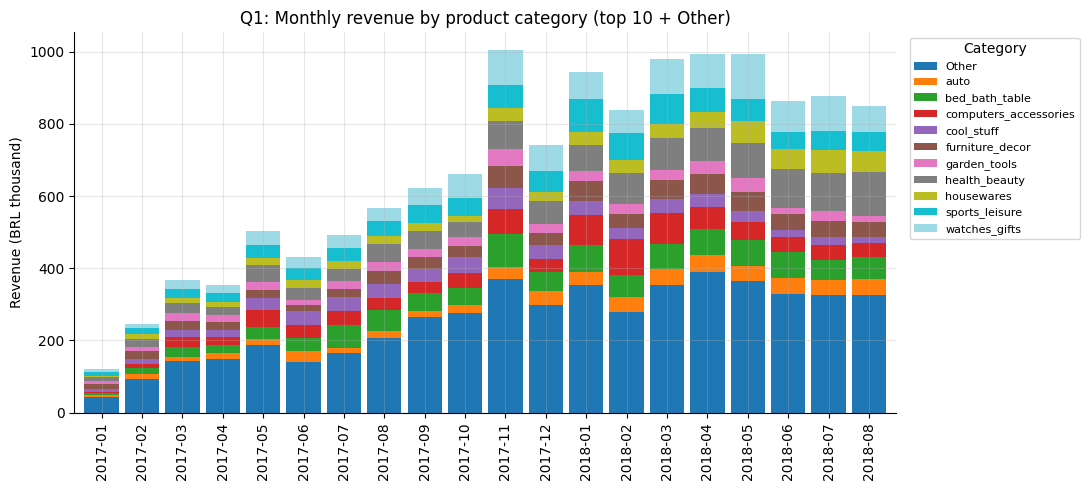

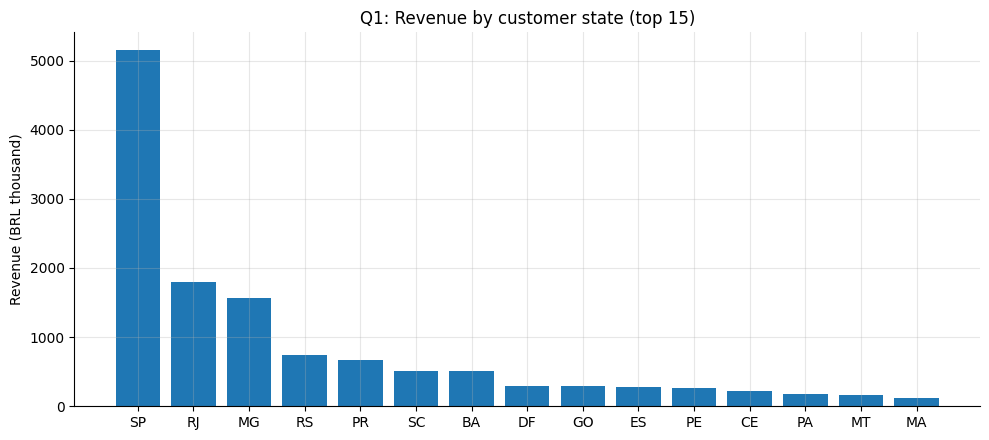

,customer_state,orders,revenue
0,SP,41021,5150778.70
1,RJ,12654,1802436.24
2,MG,11457,1568855.98
3,RS,5395,739357.46
4,PR,4962,674867.55
5,SC,3590,516340.22
6,BA,3340,506214.78
7,DF,2114,299842.68
8,GO,1990,286886.07
9,ES,2014,272614.34


In [213]:
c = q('''
WITH top_categories AS (
    SELECT category_english FROM gold.agg_monthly_revenue
    WHERE NOT is_partial_month GROUP BY category_english ORDER BY SUM(revenue) DESC LIMIT 10
),
labelled AS (
    SELECT m.year_month, COALESCE(t.category_english, 'Other') AS category, m.revenue
    FROM gold.agg_monthly_revenue m LEFT JOIN top_categories t ON m.category_english = t.category_english
    WHERE NOT m.is_partial_month
)
SELECT year_month, category, ROUND(SUM(revenue), 2) AS revenue FROM labelled GROUP BY year_month, category
''')
pv = c.pivot(index="year_month", columns="category", values="revenue").fillna(0) / 1e3
fig, ax = plt.subplots(figsize=(11, 5))
pv.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.85)
ax.set_ylabel("Revenue (BRL thousand)"); ax.set_xlabel("")
ax.set_title("Q1: Monthly revenue by product category (top 10 + Other)")
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save(fig, "q1b_revenue_by_category")

# ---------- next chart ----------
# Chart 1C: revenue by customer state (top 15)
s = q('''
SELECT c.customer_state, COUNT(*) AS orders, ROUND(SUM(f.order_revenue), 2) AS revenue
FROM gold.fact_orders f
JOIN gold.dim_customer c ON f.customer_key = c.customer_key
JOIN gold.dim_date d ON f.purchase_date_key = d.date_key
WHERE f.order_status NOT IN ('canceled', 'unavailable') AND f.item_count > 0 AND NOT d.is_partial_month
GROUP BY c.customer_state ORDER BY revenue DESC LIMIT 15
''')
fig, ax = plt.subplots()
ax.bar(s["customer_state"], s["revenue"] / 1e3, color="tab:blue")
ax.set_ylabel("Revenue (BRL thousand)")
ax.set_title("Q1: Revenue by customer state (top 15)")
save(fig, "q1c_revenue_by_state")
display(s)

# Chart 2A: late rate by seller state

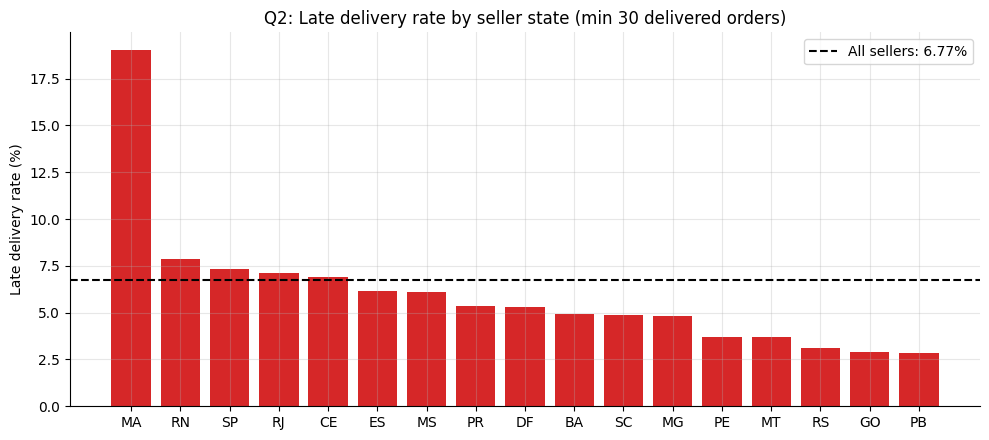

,seller_state,delivered_orders,late_rate_pct,avg_review_score,revenue
0,MA,389,19.02,3.99,36097.98
1,RN,51,7.84,4.27,9992.60
2,SP,68635,7.31,4.11,8508540.28
3,RJ,4227,7.12,4.21,820611.59
4,CE,87,6.90,4.29,19517.84
5,ES,310,6.13,4.11,46941.64
6,MS,49,6.12,4.39,8551.69
7,PR,7512,5.35,4.17,1232096.99
8,DF,808,5.32,4.09,94840.31
9,BA,550,4.91,4.19,277925.51


In [214]:
a = q('''
SELECT seller_state, delivered_orders, late_rate_pct, avg_review_score, revenue
FROM gold.agg_delivery_by_seller_state WHERE meets_min_volume ORDER BY late_rate_pct DESC
''')
overall = q("SELECT ROUND(100 * AVG(is_late), 2) AS r FROM gold.fact_orders WHERE is_delivered")["r"][0]
fig, ax = plt.subplots()
ax.bar(a["seller_state"], a["late_rate_pct"], color="tab:red")
ax.axhline(overall, color="black", linestyle="--", label=f"All sellers: {overall}%")
ax.set_ylabel("Late delivery rate (%)"); ax.legend()
ax.set_title("Q2: Late delivery rate by seller state (min 30 delivered orders)")
save(fig, "q2a_late_rate_seller_state")
display(a)

Chart 2B: top 15 sellers by late rate (seller ids shortened, anonymous)

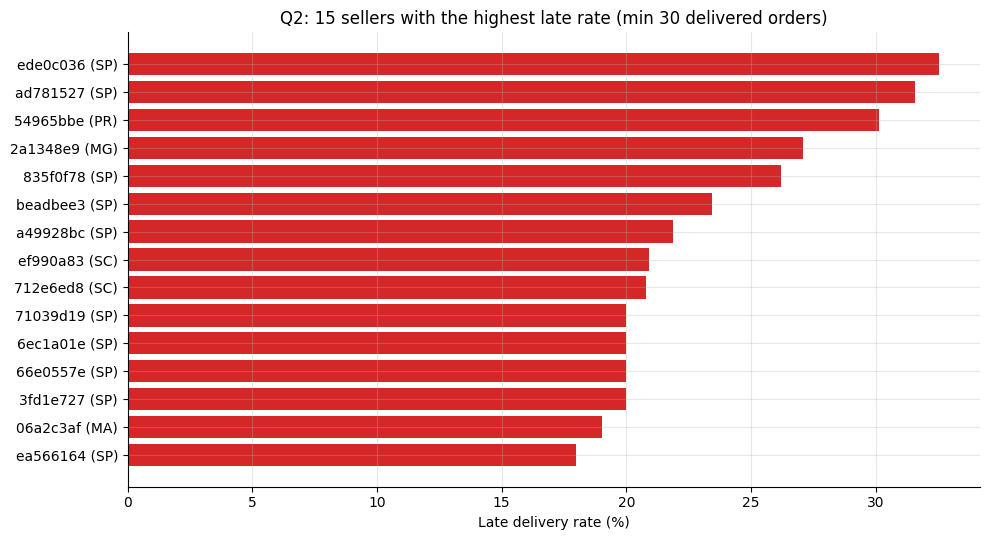

,seller,delivered_orders,late_orders,late_rate_pct,avg_review_score,revenue
0,ede0c036 (SP),43,14,32.56,3.51,2352.15
1,ad781527 (SP),38,12,31.58,3.34,6039.63
2,54965bbe (PR),73,22,30.14,3.03,10351.70
3,2a1348e9 (MG),48,13,27.08,3.13,2697.40
4,835f0f78 (SP),42,11,26.19,3.36,4990.20
5,beadbee3 (SP),64,15,23.44,3.91,4373.98
6,a49928bc (SP),96,21,21.88,3.03,8646.90
7,ef990a83 (SC),43,9,20.93,3.63,4642.59
8,712e6ed8 (SC),77,16,20.78,3.36,39385.00
9,71039d19 (SP),35,7,20.00,3.80,3537.20


In [215]:
b = q('''
SELECT CONCAT(SUBSTRING(seller_id, 1, 8), ' (', seller_state, ')') AS seller,
       delivered_orders, late_orders, late_rate_pct, avg_review_score, revenue
FROM gold.agg_delivery_by_seller WHERE meets_min_volume ORDER BY late_rate_pct DESC LIMIT 15
''')
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(b["seller"][::-1], b["late_rate_pct"][::-1], color="tab:red")
ax.set_xlabel("Late delivery rate (%)")
ax.set_title("Q2: 15 sellers with the highest late rate (min 30 delivered orders)")
save(fig, "q2b_late_rate_top_sellers")
display(b)

# Chart 2C: top 15 categories by late rate

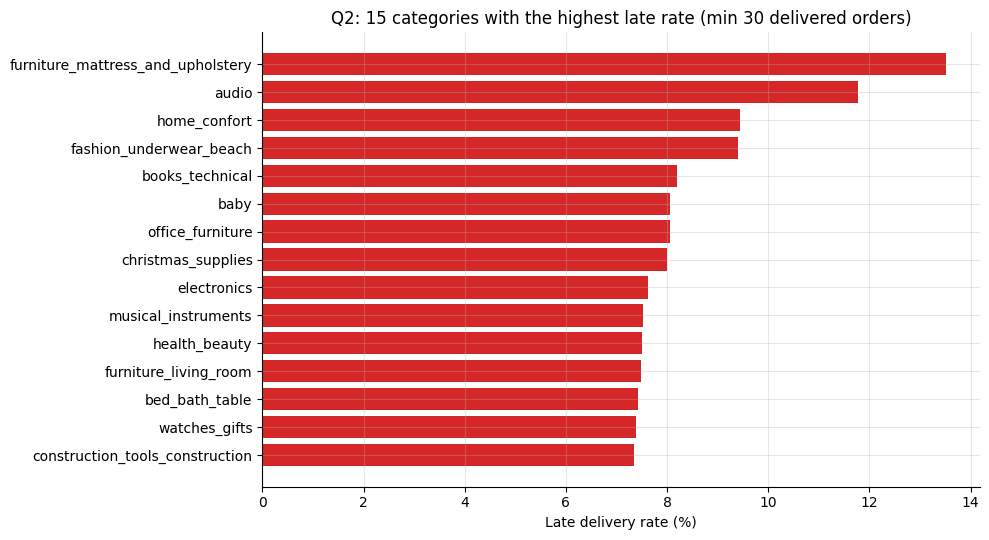

,category_english,delivered_orders,late_orders,late_rate_pct,avg_review_score,revenue
0,furniture_mattress_and_upholstery,37,5,13.51,3.89,4323.38
1,audio,348,41,11.78,3.82,50570.60
2,home_confort,392,37,9.44,3.88,58008.45
3,fashion_underwear_beach,117,11,9.40,3.98,9305.95
4,books_technical,256,21,8.20,4.41,18702.23
5,baby,2809,226,8.05,4.09,400421.84
6,office_furniture,1254,101,8.05,3.64,268154.31
7,christmas_supplies,125,10,8.00,4.10,8737.84
8,electronics,2517,192,7.63,4.11,155043.93
9,musical_instruments,611,46,7.53,4.22,184315.74


In [216]:
cat = q('''
SELECT category_english, delivered_orders, late_orders, late_rate_pct, avg_review_score, revenue
FROM gold.agg_delivery_by_category WHERE meets_min_volume ORDER BY late_rate_pct DESC LIMIT 15
''')
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(cat["category_english"][::-1], cat["late_rate_pct"][::-1], color="tab:red")
ax.set_xlabel("Late delivery rate (%)")
ax.set_title("Q2: 15 categories with the highest late rate (min 30 delivered orders)")
save(fig, "q2c_late_rate_top_categories")
display(cat)

Chart 2D: monthly late rate and average review score

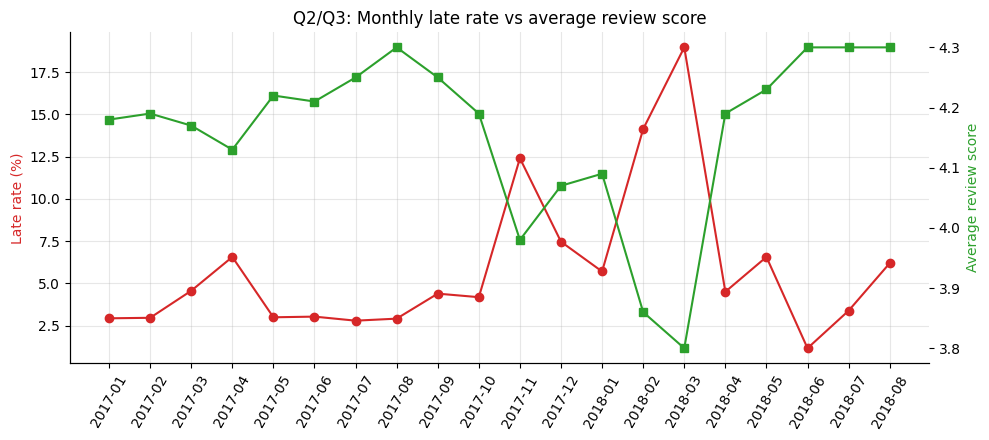

In [217]:
t = q('''
SELECT year_month, delivered_orders, late_rate_pct, avg_review_score
FROM gold.agg_monthly_delivery WHERE NOT is_partial_month ORDER BY year_month
''')
fig, ax1 = plt.subplots()
ax1.plot(t["year_month"], t["late_rate_pct"], color="tab:red", marker="o")
ax1.set_ylabel("Late rate (%)", color="tab:red")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(t["year_month"], t["avg_review_score"], color="tab:green", marker="s")
ax2.set_ylabel("Average review score", color="tab:green")
ax1.set_title("Q2/Q3: Monthly late rate vs average review score")
ax1.tick_params(axis="x", rotation=60)
save(fig, "q2d_monthly_late_rate_vs_review")

# Chart 3A: average review score by how late the order was


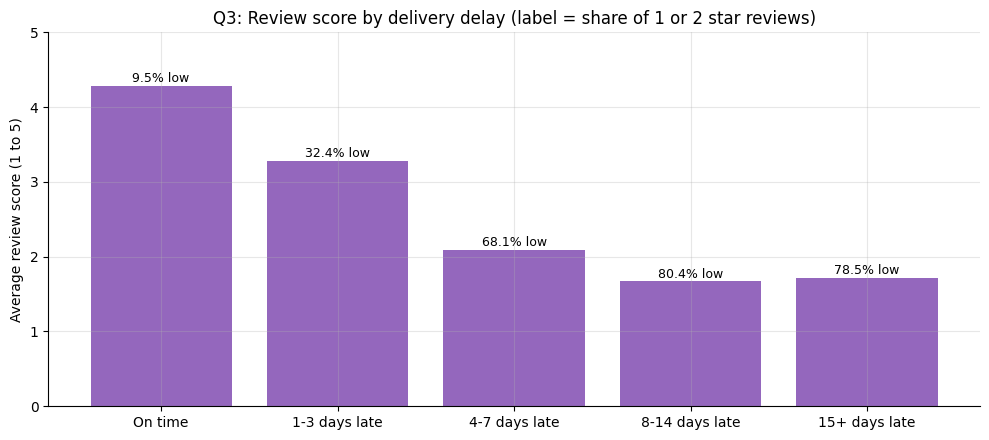

,delay_bucket,delay_bucket_sort,orders,avg_review_score,low_review_pct,revenue,revenue_share_pct
0,On time,0,89936,4.28,9.5,12234324.59,92.54
1,1-3 days late,1,1870,3.28,32.4,250856.63,1.90
2,4-7 days late,2,1802,2.09,68.1,287685.63,2.18
3,8-14 days late,3,1478,1.67,80.4,229872.60,1.74
4,15+ days late,4,1384,1.72,78.5,217509.48,1.65


,delivery,orders,avg_review_score,low_review_pct,revenue
0,On time,89936,4.28,9.5,12234324.59
1,Late,6534,2.26,62.9,985924.34


In [218]:
r = q('''
SELECT delay_bucket, delay_bucket_sort, orders, avg_review_score, low_review_pct, revenue, revenue_share_pct
FROM gold.agg_review_impact WHERE delay_bucket_sort < 9 ORDER BY delay_bucket_sort
''')
fig, ax = plt.subplots()
bars = ax.bar(r["delay_bucket"], r["avg_review_score"], color="tab:purple")
for bar, low in zip(bars, r["low_review_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f"{low}% low", ha="center", fontsize=9)
ax.set_ylim(0, 5); ax.set_ylabel("Average review score (1 to 5)")
ax.set_title("Q3: Review score by delivery delay (label = share of 1 or 2 star reviews)")
save(fig, "q3a_review_by_delay")
display(r)

hl = q('''
SELECT CASE WHEN is_late = 1 THEN 'Late' ELSE 'On time' END AS delivery,
       COUNT(*) AS orders, ROUND(AVG(review_score), 2) AS avg_review_score,
       ROUND(100 * AVG(is_low_review), 1) AS low_review_pct, ROUND(SUM(order_revenue), 2) AS revenue
FROM gold.fact_orders WHERE is_delivered
GROUP BY CASE WHEN is_late = 1 THEN 'Late' ELSE 'On time' END ORDER BY delivery DESC
''')
display(hl)

# Chart 3C: revenue held by sellers grouped by late-rate decile (decile 1 = worst 10 percent)

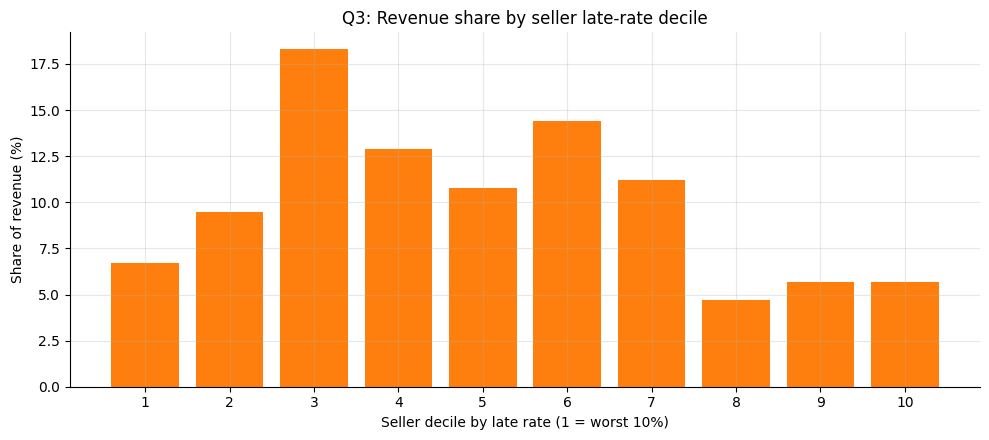

,decile,sellers,avg_late_rate_pct,avg_review_score,revenue,revenue_share_pct
0,1,63,16.9,3.77,685094.37,6.7
1,2,63,11.2,4.00,971009.04,9.5
2,3,63,9.1,4.10,1869323.68,18.3
3,4,63,7.4,4.14,1319156.77,12.9
4,5,63,6.1,4.09,1099052.75,10.8
5,6,63,4.9,4.22,1469320.67,14.4
6,7,63,3.9,4.20,1143016.78,11.2
7,8,62,3.1,4.26,478753.88,4.7
8,9,62,2.1,4.29,579826.64,5.7
9,10,62,0.3,4.34,583630.29,5.7


In [219]:
dd = q('''
WITH ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY late_rate_pct DESC) AS decile
    FROM gold.agg_delivery_by_seller WHERE meets_min_volume
)
SELECT decile, COUNT(*) AS sellers, ROUND(AVG(late_rate_pct), 1) AS avg_late_rate_pct,
       ROUND(AVG(avg_review_score), 2) AS avg_review_score, ROUND(SUM(revenue), 2) AS revenue,
       ROUND(100 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS revenue_share_pct
FROM ranked GROUP BY decile ORDER BY decile
''')
fig, ax = plt.subplots()
ax.bar(dd["decile"].astype(str), dd["revenue_share_pct"], color="tab:orange")
ax.set_xlabel("Seller decile by late rate (1 = worst 10%)"); ax.set_ylabel("Share of revenue (%)")
ax.set_title("Q3: Revenue share by seller late-rate decile")
save(fig, "q3c_revenue_by_late_decile")
display(dd)

# Worst groups with revenue (table for the recommendation)

In [220]:
display(q('''
SELECT 'seller state' AS group_type, seller_state AS group_name, delivered_orders, late_rate_pct, avg_review_score, revenue, late_revenue
FROM gold.agg_delivery_by_seller_state WHERE meets_min_volume
UNION ALL
SELECT 'category', category_english, delivered_orders, late_rate_pct, avg_review_score, revenue, late_revenue
FROM gold.agg_delivery_by_category WHERE meets_min_volume
UNION ALL
SELECT 'customer state', customer_state, delivered_orders, late_rate_pct, avg_review_score, revenue, late_revenue
FROM gold.agg_delivery_by_customer_state WHERE meets_min_volume
ORDER BY late_rate_pct DESC LIMIT 20
'''))

,group_type,group_name,delivered_orders,late_rate_pct,avg_review_score,revenue,late_revenue
0,customer state,AL,397,21.41,3.83,78855.72,18083.67
1,seller state,MA,389,19.02,3.99,36097.98,6564.22
2,customer state,MA,717,17.43,3.81,117009.38,22865.56
3,customer state,SE,335,15.22,3.90,56574.19,10276.37
4,customer state,PI,476,13.87,3.98,84721.00,11414.94
5,customer state,CE,1279,13.76,3.94,219757.38,30604.18
6,category,furniture_mattress_and_upholstery,37,13.51,3.89,4323.38,553.70
7,customer state,RR,41,12.20,3.90,7057.47,1288.89
8,customer state,BA,3256,12.16,3.91,493584.14,62058.74
9,customer state,RJ,12350,12.11,3.95,1759651.13,215415.46
